# TP4 · Fêtes et consommation au Sénégal
**Python avancé, L3 Intelligence Artificielle, ISM** · Hamze Abdoulkarim Aden · Enseignant : Elias BADJI

> **Données fictives.** Toutes les données sont simulées à des fins pédagogiques. Elles ne décrivent pas le comportement réel des Sénégalais ni d'aucune communauté religieuse, et aucune conclusion sur une communauté n'est tirée de ce travail.

**Les quatre questions de la direction**
1. **Mesurer** : quels produits s'envolent avant chaque fête, de combien, et dans quelles villes ?
2. **Prévoir** : peut-on prévoir la demande de 2025 avec un an d'avance ?
3. **Comprendre** : quels ménages s'endettent après une fête, et pourquoi ?
4. **Agir** : quelles quantités prévoir pour les fêtes de 2026 ?

**Sommaire** : 0. Configuration · 1. Audit et nettoyage · 2. Variables d'événement · 3. Effet des fêtes · Bonus promotions · 4. Prévision à un an · Bonus quantiles · 5. Endettement et équité · 6. Profils de dépense · 7. Plan 2026

## Partie 0 · Configuration

In [1]:
# === Imports ===
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

# === Interrupteur : False = recharger ce qui est déjà sauvegardé, True = tout recalculer ===
RECALCULER = True

# === Reproductibilité : la même graine partout ===
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# === Chemins : le notebook est dans notebooks/, la racine du projet est le dossier parent ===
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DOSSIER_RAW = RACINE / "data" / "raw"
DOSSIER_PROCESSED = RACINE / "data" / "processed"
DOSSIER_MODELES = RACINE / "models"
DOSSIER_RAPPORTS = RACINE / "reports"
DOSSIER_FIGURES = DOSSIER_RAPPORTS / "figures"

# Ces dossiers sont ignorés par git : on les recrée s'ils n'existent pas (après un clone par exemple)
for dossier in [DOSSIER_PROCESSED, DOSSIER_MODELES, DOSSIER_FIGURES]:
    dossier.mkdir(parents=True, exist_ok=True)

# === Affichage ===
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100


# === Fonctions utilitaires ===
def sauver_figure(fig, nom):
    """Enregistre une figure en PNG dans reports/figures/ (nom sans extension)."""
    chemin = DOSSIER_FIGURES / f"{nom}.png"
    fig.savefig(chemin, dpi=150, bbox_inches="tight")
    print("Figure enregistrée :", chemin.name)


def chemin_parquet(nom):
    """Chemin d'un fichier intermédiaire dans data/processed/."""
    return DOSSIER_PROCESSED / f"{nom}.parquet"


def chemin_modele(nom):
    """Chemin d'un modèle sauvegardé avec joblib dans models/."""
    return DOSSIER_MODELES / f"{nom}.joblib"


def peut_recharger(*chemins):
    """True si RECALCULER vaut False ET que tous les fichiers demandés existent déjà."""
    return (not RECALCULER) and all(Path(c).exists() for c in chemins)


print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("Racine du projet :", RACINE)
print("Fichiers bruts :", sorted(p.name for p in DOSSIER_RAW.glob("*.csv")))

pandas 3.0.6 | scikit-learn 1.9.1
Racine du projet : c:\Users\User\Desktop\L3S5\Python avance\TP4\fetes-consommation-senegal
Fichiers bruts : ['calendrier_evenements.csv', 'categories.csv', 'enquete_menages.csv', 'magasins.csv', 'ventes_journalieres.csv']


## Partie 1 · Audit et nettoyage

### 1.1 Chargement des données

In [2]:
# Ventes : dates parsées, textes répétitifs en category ; les colonnes numériques sont laissées à pandas
# (si l'une contient du texte, elle ne sera pas numérique, et ce sera un défaut à traiter)
ventes_brutes = pd.read_csv(
    DOSSIER_RAW / "ventes_journalieres.csv",
    parse_dates=["date"],
    dtype={"magasin_id": "category", "categorie": "category"},
)

# Tables de référence
magasins = pd.read_csv(DOSSIER_RAW / "magasins.csv", parse_dates=["date_ouverture"])
categories = pd.read_csv(DOSSIER_RAW / "categories.csv")
calendrier = pd.read_csv(DOSSIER_RAW / "calendrier_evenements.csv", parse_dates=["date_debut", "date_fin"])

print("Ventes :", ventes_brutes.shape, "| Magasins :", magasins.shape,
      "| Catégories :", categories.shape, "| Calendrier :", calendrier.shape)
ventes_brutes.info(memory_usage="deep")
ventes_brutes.head()

Ventes : (530790, 8) | Magasins : (10, 6) | Catégories : (15, 4) | Calendrier : (103, 7)
<class 'pandas.DataFrame'>
RangeIndex: 530790 entries, 0 to 530789
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   date                   530790 non-null  datetime64[us]
 1   magasin_id             530790 non-null  category      
 2   categorie              530790 non-null  category      
 3   quantite               529730 non-null  float64       
 4   prix_unitaire_fcfa     530790 non-null  float64       
 5   promo                  530790 non-null  int64         
 6   part_paiement_mobile   530790 non-null  float64       
 7   chiffre_affaires_fcfa  529730 non-null  float64       
dtypes: category(2), datetime64[us](1), float64(4), int64(1)
memory usage: 25.3 MB


,date,magasin_id,categorie,quantite,prix_unitaire_fcfa,promo,part_paiement_mobile,chiffre_affaires_fcfa
0,2016-01-01,M01,arachide_bouye,31.0,1175.0,0,0.034,36425.0
1,2016-01-01,M01,beaute_coiffure,46.0,2500.0,0,0.018,115000.0
2,2016-01-01,M01,betail_mouton,0.0,89500.0,0,0.000,0.0
3,2016-01-01,M01,boissons,265.0,500.0,0,0.000,132500.0
4,2016-01-01,M01,cereales_mil,56.0,375.0,0,0.008,21000.0


In [3]:
print("Type de la colonne date :", ventes_brutes["date"].dtype)
print("Période couverte :", ventes_brutes["date"].min().date(), "->", ventes_brutes["date"].max().date())

print("\nLignes par magasin :")
print(ventes_brutes["magasin_id"].value_counts().sort_index().to_string())

print("\nCatégories trouvées dans les ventes (avec effectifs) :")
print(ventes_brutes["categorie"].value_counts().sort_index().to_string())
print("\nCatégories officielles (categories.csv) :", categories["categorie"].tolist())

ventes_brutes.describe().T

Type de la colonne date : datetime64[us]
Période couverte : 2016-01-01 -> 2025-12-31

Lignes par magasin :
magasin_id
M01    54837
M02    54826
M03    54703
M04    54826
M05    54825
M06    49332
M07    54825
M08    54822
M09    54822
M10    42972

Catégories trouvées dans les ventes (avec effectifs) :
categorie
Arachide_bouye             9
BEAUTE_COIFFURE           17
BETAIL_MOUTON             13
Beaute_coiffure           15
Boissons                  14
CEREALES_MIL              10
CREDIT_MOBILE              9
DATTES                    11
Dattes                    12
HUILE                      8
Huile                     13
JOUETS_CADEAUX            12
Jouets_cadeaux            13
LAIT                      11
Oignons                   13
RIZ                       15
Riz                        9
SUCRE                     10
Sucre                     10
TISSUS_HABILLEMENT         7
Tissus_habillement        11
VOLAILLE                  12
arachide_bouye         35348
arachide_bouye     

,count,mean,min,25%,50%,75%,max,std
date,530790,2021-02-17 22:19:46.882948,2016-01-01 00:00:00,2018-09-26 00:00:00,2021-02-26 00:00:00,2023-07-31 00:00:00,2025-12-31 00:00:00,NaN
quantite,529730.0,119.111982,-607.0,20.0,64.0,178.0,51000.0,186.312986
prix_unitaire_fcfa,530790.0,10095.579796,250.0,550.0,1400.0,2875.0,204000.0,31227.265444
promo,530790.0,0.042791,0.0,0.0,0.0,0.0,1.0,0.202386
part_paiement_mobile,530790.0,0.153309,0.0,0.042,0.088,0.232,0.708,0.152946
chiffre_affaires_fcfa,529730.0,118347.579144,-349350.0,33350.0,85625.0,159075.0,34540000.0,165548.204541


### 1.2 Audit : mesure des défauts (aucune correction à ce stade)

In [4]:
# Catégories mal saisies
import unicodedata

CLE = ["date", "magasin_id", "categorie"]          # clé d'une ligne de vente
CATS_OFFICIELLES = set(categories["categorie"])


def normaliser_categorie(texte):
    """Ramène un libellé au format officiel : sans accents, minuscules, sans espaces autour, '_' comme séparateur."""
    texte = unicodedata.normalize("NFKD", str(texte)).encode("ascii", "ignore").decode("ascii")
    return texte.strip().lower().replace(" ", "_").replace("-", "_")


# On travaille sur les libellés distincts (quelques dizaines), pas sur les 530 000 lignes
correspondance = {lib: normaliser_categorie(lib) for lib in ventes_brutes["categorie"].cat.categories}
mal_saisis = {lib: norm for lib, norm in correspondance.items() if lib not in CATS_OFFICIELLES}
irrecuperables = {lib: norm for lib, norm in mal_saisis.items() if norm not in CATS_OFFICIELLES}

nb_lignes_mal_saisies = ventes_brutes["categorie"].isin(list(mal_saisis)).sum()
print(f"{len(mal_saisis)} libellés mal saisis, présents sur {nb_lignes_mal_saisies} lignes")
print("Libellés non récupérables après normalisation :", irrecuperables)

# Copie de travail de l'audit, avec les catégories normalisées
ventes_audit = ventes_brutes.copy()
ventes_audit["categorie"] = ventes_audit["categorie"].map(correspondance).astype("category")
print("Catégories après normalisation :", ventes_audit["categorie"].nunique())

45 libellés mal saisis, présents sur 530 lignes
Libellés non récupérables après normalisation : {}
Catégories après normalisation : 15


In [5]:
# Doublons
nb_doublons_exacts = ventes_audit.duplicated().sum()
nb_doublons_cle = ventes_audit.duplicated(subset=CLE).sum()
print("Doublons exacts (lignes entièrement identiques) :", nb_doublons_exacts)
print("Doublons sur la clé (date, magasin, catégorie)  :", nb_doublons_cle)
print("  dont doublons de clé avec des valeurs différentes :", nb_doublons_cle - nb_doublons_exacts)

print("\nDoublons de clé par magasin :")
print(ventes_audit[ventes_audit.duplicated(subset=CLE)]["magasin_id"].value_counts().sort_index().to_string())

# Exemple : quelques groupes de doublons côte à côte
masque_dup = ventes_audit.duplicated(subset=CLE, keep=False)
ventes_audit[masque_dup].sort_values(CLE).head(8)

Doublons exacts (lignes entièrement identiques) : 300
Doublons sur la clé (date, magasin, catégorie)  : 300
  dont doublons de clé avec des valeurs différentes : 0

Doublons de clé par magasin :
magasin_id
M01    42
M02    31
M03    28
M04    31
M05    30
M06    27
M07    30
M08    27
M09    27
M10    27


,date,magasin_id,categorie,quantite,prix_unitaire_fcfa,promo,part_paiement_mobile,chiffre_affaires_fcfa
2627,2016-01-22,M09,betail_mouton,0.0,89000.0,0,0.084,0.0
2628,2016-01-22,M09,betail_mouton,0.0,89000.0,0,0.084,0.0
3766,2016-02-01,M04,arachide_bouye,20.0,1200.0,0,0.006,24000.0
3767,2016-02-01,M04,arachide_bouye,20.0,1200.0,0,0.006,24000.0
4741,2016-02-09,M04,volaille,14.0,2400.0,0,0.027,33600.0
4742,2016-02-09,M04,volaille,14.0,2400.0,0,0.027,33600.0
6733,2016-02-26,M01,oignons,147.0,300.0,0,0.024,44100.0
6734,2016-02-26,M01,oignons,147.0,300.0,0,0.024,44100.0


In [6]:
# Valeurs manquantes
manquants = ventes_audit.isna().sum()
print("Valeurs manquantes :\n", manquants[manquants > 0].to_string())
memes_lignes = (ventes_audit["quantite"].isna() == ventes_audit["chiffre_affaires_fcfa"].isna()).all()
print("quantite et chiffre_affaires manquent sur les mêmes lignes :", memes_lignes)
print("Lignes manquantes par année :",
      ventes_audit.loc[ventes_audit["quantite"].isna(), "date"].dt.year.value_counts().sort_index().to_dict())

# Quantités négatives
negatifs = ventes_audit[ventes_audit["quantite"] < 0]
print("\nQuantités négatives :", len(negatifs))
print("Par catégorie :", negatifs["categorie"].value_counts().head(5).to_dict())
print("Quantiles des valeurs négatives :", negatifs["quantite"].quantile([0, 0.5, 1]).to_dict())

# Cohérence : chiffre d'affaires = quantité x prix ?
ecart_ca = (ventes_audit["chiffre_affaires_fcfa"]
            - ventes_audit["quantite"] * ventes_audit["prix_unitaire_fcfa"]).abs()
print("\nLignes où CA != quantité x prix (écart > 1 FCFA) :", (ecart_ca > 1).sum())

# Bornes des autres colonnes
print("Valeurs de promo :", sorted(ventes_audit["promo"].unique()))
print("part_paiement_mobile hors de [0, 1] :",
      (~ventes_audit["part_paiement_mobile"].between(0, 1)).sum())

Valeurs manquantes :
 quantite                 1060
chiffre_affaires_fcfa    1060
quantite et chiffre_affaires manquent sur les mêmes lignes : True
Lignes manquantes par année : {2016: 89, 2017: 83, 2018: 117, 2019: 89, 2020: 114, 2021: 111, 2022: 126, 2023: 124, 2024: 93, 2025: 114}

Quantités négatives : 29
Par catégorie : {'huile': 4, 'jouets_cadeaux': 4, 'cereales_mil': 3, 'lait': 3, 'riz': 3}
Quantiles des valeurs négatives : {0.0: -607.0, 0.5: -62.0, 1.0: -5.0}

Lignes où CA != quantité x prix (écart > 1 FCFA) : 0
Valeurs de promo : [np.int64(0), np.int64(1)]
part_paiement_mobile hors de [0, 1] : 0


In [7]:
# Valeurs aberrantes

# Quantités : rapport à la valeur du 99e percentile de chaque couple magasin x catégorie
p99 = (ventes_audit.groupby(["magasin_id", "categorie"], observed=True)["quantite"]
       .transform(lambda s: s.quantile(0.99)))
ventes_audit["ratio_p99"] = ventes_audit["quantite"] / p99

print("Nombre de lignes au-dessus de k fois le p99 :")
for k in [2, 3, 5, 10, 20]:
    print(f"  > {k:>2} x p99 : {(ventes_audit['ratio_p99'] > k).sum()}")

# Les 15 plus gros rapports, avec la date pour vérifier qu'il ne s'agit pas d'un pic de fête
display(ventes_audit.sort_values("ratio_p99", ascending=False)
        .head(15)[CLE + ["quantite", "ratio_p99", "prix_unitaire_fcfa", "promo"]])

# Prix : rapport au prix médian de la catégorie la même année
prix_median = (ventes_audit.groupby(["categorie", ventes_audit["date"].dt.year], observed=True)
               ["prix_unitaire_fcfa"].transform("median"))
ratio_prix = ventes_audit["prix_unitaire_fcfa"] / prix_median
print("Prix > 3x ou < 1/3 du prix médian (catégorie, année) :", ((ratio_prix > 3) | (ratio_prix < 1 / 3)).sum())
print("Rapport de prix min / max :", round(ratio_prix.min(), 2), "/", round(ratio_prix.max(), 2))

Nombre de lignes au-dessus de k fois le p99 :
  >  2 x p99 : 191
  >  3 x p99 : 52
  >  5 x p99 : 36
  > 10 x p99 : 36
  > 20 x p99 : 35


,date,magasin_id,categorie,quantite,ratio_p99,prix_unitaire_fcfa,promo
130176,2018-09-09,M10,riz,42900.0,92.095659,300.0,0
389325,2023-06-03,M04,riz,51000.0,74.097751,400.0,0
516192,2025-09-25,M08,cereales_mil,6300.0,68.078669,400.0,1
462199,2024-09-30,M10,huile,10700.0,67.541977,1550.0,0
117139,2018-06-15,M02,arachide_bouye,3600.0,61.485909,1300.0,0
448511,2024-07-01,M08,huile,10500.0,60.511757,1575.0,0
461505,2024-09-26,M04,boissons,25200.0,58.867501,650.0,0
242561,2020-09-27,M07,volaille,3700.0,57.355449,2575.0,0
464176,2024-10-14,M02,cereales_mil,7600.0,56.063736,450.0,0
326543,2022-04-11,M01,cereales_mil,10300.0,55.219000,375.0,1


Prix > 3x ou < 1/3 du prix médian (catégorie, année) : 0
Rapport de prix min / max : 0.77 / 1.26


In [8]:
# Jours manquants par point de vente
DEBUT, FIN = pd.Timestamp("2016-01-01"), pd.Timestamp("2025-12-31")
ouvertures = magasins.set_index("magasin_id")["date_ouverture"]

lignes_jours = []
for magasin, date_ouv in ouvertures.items():   # boucle sur les 10 magasins, pas sur les ventes
    ventes_m = ventes_audit[ventes_audit["magasin_id"] == magasin]
    jours_attendus = pd.date_range(max(DEBUT, date_ouv), FIN, freq="D")   # à partir de l'ouverture
    jours_presents = pd.DatetimeIndex(ventes_m["date"].unique())
    jours_manquants = jours_attendus.difference(jours_presents)
    combis_presentes = ventes_m.drop_duplicates(subset=CLE)
    combis_presentes = combis_presentes[combis_presentes["date"] >= date_ouv]
    lignes_jours.append({
        "magasin_id": magasin,
        "ouverture": date_ouv.date(),
        "jours_attendus": len(jours_attendus),
        "jours_manquants": len(jours_manquants),
        "combinaisons_manquantes": len(jours_attendus) * len(CATS_OFFICIELLES) - len(combis_presentes),
        "lignes_avant_ouverture": int((ventes_m["date"] < date_ouv).sum()),
        "exemples_dates_manquantes": [d.date().isoformat() for d in jours_manquants[:5]],
    })

audit_jours = pd.DataFrame(lignes_jours)
audit_jours

,magasin_id,ouverture,jours_attendus,jours_manquants,combinaisons_manquantes,lignes_avant_ouverture,exemples_dates_manquantes
0,M01,2016-01-01,3653,0,0,0,[]
1,M02,2016-01-01,3653,0,0,0,[]
2,M03,2016-01-01,3653,8,120,0,"[2021-03-05, 2021-03-06, 2021-03-07, 2021-03-0..."
3,M04,2016-01-01,3653,0,0,0,[]
4,M05,2016-01-01,3653,0,0,0,[]
5,M06,2017-01-01,3287,0,0,0,[]
6,M07,2016-01-01,3653,0,0,0,[]
7,M08,2016-01-01,3653,0,0,0,[]
8,M09,2016-01-01,3653,0,0,0,[]
9,M10,2018-03-01,2863,0,0,0,[]


### 1.3 Traitements et rapport d'audit

In [9]:
# Vérifier que les fortes valeurs restantes sont des pics de fête

# Lignes entre 3x et 10x le p99 : on vérifie qu'elles tombent juste avant une fête (pics réels, à garder)
fortes = ventes_audit[ventes_audit["ratio_p99"].between(3, 10)].sort_values("date")

# Fête la plus proche APRÈS chaque date (merge_asof en avant), pour voir si c'est un pic d'avant-fête
fetes_j0 = calendrier[["date_debut", "evenement"]].sort_values("date_debut")
fortes = pd.merge_asof(fortes, fetes_j0, left_on="date", right_on="date_debut", direction="forward")
fortes["jours_avant_fete"] = (fortes["date_debut"] - fortes["date"]).dt.days
fortes[["date", "magasin_id", "categorie", "quantite", "ratio_p99", "evenement", "jours_avant_fete"]]

,date,magasin_id,categorie,quantite,ratio_p99,evenement,jours_avant_fete
0,2016-09-10,M07,betail_mouton,6.0,3.000000,Tabaski,2
1,2016-09-11,M09,betail_mouton,6.0,3.000000,Tabaski,1
2,2017-08-30,M02,betail_mouton,9.0,3.000000,Tabaski,3
3,2017-09-01,M09,betail_mouton,7.0,3.500000,Tabaski,1
4,2018-08-17,M09,betail_mouton,6.0,3.000000,Tabaski,5
5,2018-08-18,M10,betail_mouton,6.0,3.000000,Tabaski,4
6,2018-08-19,M07,betail_mouton,8.0,4.000000,Tabaski,3
7,2018-08-21,M01,betail_mouton,11.0,3.133903,Tabaski,1
8,2019-08-10,M01,betail_mouton,13.0,3.703704,Tabaski,2
9,2019-08-11,M09,betail_mouton,6.0,3.000000,Tabaski,1


In [10]:
# Nettoyage (avec l’interrupteur RECALCULER)
SEUIL_ABERRANT = 10   # Choix : au-delà de 10 fois le p99 du couple magasin x catégorie, c'est une erreur de saisie


def nettoyer_ventes(brutes, nb_jours_manquants):
    """Applique les traitements de l'audit. Renvoie les ventes nettoyées et le rapport d'audit chiffré."""
    df = brutes.copy()
    n_initial = len(df)
    rapport = []

    # 1. Catégories mal saisies -> libellé officiel
    mal_saisie = ~df["categorie"].isin(list(CATS_OFFICIELLES))
    corr = {lib: normaliser_categorie(lib) for lib in df["categorie"].cat.categories}
    df["categorie"] = df["categorie"].map(corr).astype("category")
    rapport.append(("Catégories mal saisies (casse, espaces)", mal_saisie.sum(),
                    "Ramenées au libellé officiel : c'est le même produit écrit autrement."))

    # 2. Doublons exacts -> supprimés
    doublon = df.duplicated()
    df = df[~doublon].copy()
    rapport.append(("Doublons exacts", doublon.sum(),
                    "Supprimés : sinon les ventes de ce jour seraient comptées deux fois."))

    # 3. Valeurs manquantes d'origine (quantité et CA sur les mêmes lignes)
    manquant = df["quantite"].isna()
    rapport.append(("Quantité et CA manquants", manquant.sum(),
                    "Imputés par interpolation dans le temps (même magasin, même catégorie)."))

    # 4. Quantités négatives -> NaN (une vente journalière ne peut pas être négative)
    negatif = df["quantite"] < 0
    rapport.append(("Quantités négatives", negatif.sum(),
                    "Mises à NaN puis imputées comme les manquants : valeur impossible."))

    # 5. Valeurs aberrantes -> NaN (erreur de saisie isolée, bien au-delà des pics de fête)
    p99 = (df.groupby(["magasin_id", "categorie"], observed=True)["quantite"]
           .transform(lambda s: s.quantile(0.99)))
    aberrant = df["quantite"] > SEUIL_ABERRANT * p99
    rapport.append((f"Quantités aberrantes (> {SEUIL_ABERRANT} x p99 magasin x catégorie)", aberrant.sum(),
                    "Mises à NaN puis imputées : 45 à 92 fois le p99, aucun point entre 5x et 10x."))
    df.loc[negatif | aberrant, "quantite"] = np.nan

    # Imputation : interpolation linéaire dans chaque série magasin x catégorie, triée par date
    df = df.sort_values(["magasin_id", "categorie", "date"]).reset_index(drop=True)
    df["quantite_imputee"] = df["quantite"].isna()      # trace des lignes imputées (exclues du WAPE en partie 4)
    df["quantite"] = (df.groupby(["magasin_id", "categorie"], observed=True)["quantite"]
                      .transform(lambda s: s.interpolate(limit_direction="both"))
                      .round())
    # Le CA est recalculé : l'audit a montré que CA = quantité x prix sur toutes les lignes
    df["chiffre_affaires_fcfa"] = df["quantite"] * df["prix_unitaire_fcfa"]

    # 6. Défauts mesurés mais sans correction sur les lignes
    rapport.append(("Lignes manquantes (M03 : 8 jours x 15 catégories, à partir du 2021-03-05)", nb_jours_manquants,
                    "Non recréés : on ne sait pas si le magasin était fermé ; les uplifts sont des moyennes par jour disponible."))
    rapport.append(("Ventes avant la date d'ouverture", 0,
                    "Aucune : les années sans ventes de M06 et M10 ne sont pas des jours manquants."))
    rapport.append(("Prix aberrants (> 3x ou < 1/3 de la médiane)", 0, "Aucun traitement nécessaire."))
    rapport.append(("Incohérences CA != quantité x prix", 0, "Aucune ; CA recalculé après correction des quantités."))

    rapport = pd.DataFrame(rapport, columns=["defaut", "lignes_concernees", "traitement"])
    rapport["lignes_concernees"] = rapport["lignes_concernees"].astype(int)
    rapport["pct_lignes"] = (100 * rapport["lignes_concernees"] / n_initial).round(3)

    # Types finaux et ordre naturel (date, magasin, catégorie)
    df["promo"] = df["promo"].astype("int8")
    df = df.sort_values(CLE).reset_index(drop=True)
    return df, rapport[["defaut", "lignes_concernees", "pct_lignes", "traitement"]]


if peut_recharger(chemin_parquet("ventes_propres"), chemin_parquet("rapport_audit")):
    ventes = pd.read_parquet(chemin_parquet("ventes_propres"))
    rapport_audit = pd.read_parquet(chemin_parquet("rapport_audit"))
    print("Ventes nettoyées rechargées depuis data/processed/")
else:
    ventes, rapport_audit = nettoyer_ventes(ventes_brutes, int(audit_jours["combinaisons_manquantes"].sum()))
    ventes.to_parquet(chemin_parquet("ventes_propres"), index=False)
    rapport_audit.to_parquet(chemin_parquet("rapport_audit"), index=False)
    print("Ventes nettoyées calculées et sauvegardées")

rapport_audit

Ventes nettoyées calculées et sauvegardées


,defaut,lignes_concernees,pct_lignes,traitement
0,"Catégories mal saisies (casse, espaces)",530,0.100,Ramenées au libellé officiel : c'est le même p...
1,Doublons exacts,300,0.057,Supprimés : sinon les ventes de ce jour seraie...
2,Quantité et CA manquants,1060,0.200,Imputés par interpolation dans le temps (même ...
3,Quantités négatives,29,0.005,Mises à NaN puis imputées comme les manquants ...
4,Quantités aberrantes (> 10 x p99 magasin x cat...,36,0.007,Mises à NaN puis imputées : 45 à 92 fois le p9...
5,Lignes manquantes (M03 : 8 jours x 15 catégori...,120,0.023,Non recréés : on ne sait pas si le magasin éta...
6,Ventes avant la date d'ouverture,0,0.000,Aucune : les années sans ventes de M06 et M10 ...
7,Prix aberrants (> 3x ou < 1/3 de la médiane),0,0.000,Aucun traitement nécessaire.
8,Incohérences CA != quantité x prix,0,0.000,Aucune ; CA recalculé après correction des qua...


In [11]:
# Vérification du nettoyage
print("Lignes avant / après :", len(ventes_brutes), "/", len(ventes), "(attendu : 530 490)")
print("Valeurs manquantes restantes :", int(ventes.isna().sum().sum()))
print("Quantités négatives restantes :", int((ventes["quantite"] < 0).sum()))
print("Doublons de clé restants :", int(ventes.duplicated(subset=CLE).sum()))
print("Catégories :", ventes["categorie"].nunique(), "| Lignes imputées :", int(ventes["quantite_imputee"].sum()))
print("Quantité max après nettoyage :", ventes["quantite"].max())
print("Jours manquants de M03 :", audit_jours.loc[audit_jours["magasin_id"] == "M03", "exemples_dates_manquantes"].item(),
      "... (8 jours au total)")
ventes.dtypes

Lignes avant / après : 530790 / 530490 (attendu : 530 490)
Valeurs manquantes restantes : 0
Quantités négatives restantes : 0
Doublons de clé restants : 0
Catégories : 15 | Lignes imputées : 1125
Quantité max après nettoyage : 4946.0
Jours manquants de M03 : ['2021-03-05', '2021-03-06', '2021-03-07', '2021-03-08', '2021-03-09'] ... (8 jours au total)


date                     datetime64[us]
magasin_id                     category
categorie                      category
quantite                        float64
prix_unitaire_fcfa              float64
promo                              int8
part_paiement_mobile            float64
chiffre_affaires_fcfa           float64
quantite_imputee                   bool
dtype: object

### Conclusion de la partie 1

Le fichier brut compte 530 790 lignes. Après nettoyage il en reste **530 490**, exactement le nombre attendu : 10 magasins × 15 catégories sur leurs jours d'ouverture, moins les 120 combinaisons absentes de M03. Les défauts touchent moins de 0,4 % des lignes. On trouve 530 lignes aux libellés de catégorie mal saisis (45 variantes de casse ou d'espaces, toutes récupérées) et **300 doublons exacts**, supprimés. S'y ajoutent **1 060 quantités manquantes**, **29 quantités négatives** et **36 quantités aberrantes**, ces dernières valant 45 à 92 fois le 99e percentile de leur série. Ces 1 125 valeurs ont été imputées par interpolation dans le temps, à l'intérieur de leur série magasin × catégorie, et la colonne `quantite_imputee` les repère pour les exclure de l'évaluation en partie 4. Les fortes valeurs conservées, jusqu'à 4 fois le p99, tombent toutes 1 à 5 jours avant la Tabaski, Pâques ou le Maouloud : ce sont des pics de fête, pas des anomalies. Les 8 jours manquants de M03 (à partir du 5 mars 2021) n'ont pas été recréés. Les années sans ventes de M06 (avant 2017) et de M10 (avant mars 2018) correspondent à leurs dates d'ouverture et non à des trous. Enfin, les prix, les promotions, la part de paiement mobile et la relation CA = quantité × prix ne présentent aucun défaut.

## Partie 2 · Variables d'événement

### 2.1 Distances aux fêtes avec `merge_asof`

la fonction

In [12]:
# Nom court de chaque fête du calendrier (utilisé dans les noms de colonnes av_ / ap_)
FETES = {
    "Ramadan": "ramadan",
    "Korité": "korite",
    "Tabaski": "tabaski",
    "Tamkharit": "tamkharit",
    "Magal de Touba": "magal",
    "Maouloud": "maouloud",
    "Pâques": "paques",
    "Pèlerinage de Popenguine": "popenguine",
    "Noël": "noel",
}
PLAFOND = 60   # Choix : au-delà de 60 jours, la fête n'a plus d'effet ; sert aussi quand il n'y a pas d'occurrence


def variables_calendrier(dates, calendrier=calendrier, plafond=PLAFOND):
    """Pour chaque date unique : jours AVANT la prochaine occurrence (av_) et jours DEPUIS la précédente (ap_)
    de chaque fête, plafonnés, plus un indicateur ramadan. Pour le Ramadan, J0 = premier jour du jeûne."""
    base = pd.DataFrame({"date": pd.to_datetime(pd.Series(dates)).drop_duplicates().sort_values()})
    base = base.reset_index(drop=True)

    for evenement, nom in FETES.items():
        occurrences = (calendrier.loc[calendrier["evenement"] == evenement, ["date_debut"]]
                       .rename(columns={"date_debut": "date_fete"})
                       .sort_values("date_fete"))
        # Prochaine occurrence (le jour J compte : av = 0) et occurrence précédente (ap = 0 le jour J)
        suivante = pd.merge_asof(base, occurrences, left_on="date", right_on="date_fete", direction="forward")
        precedente = pd.merge_asof(base, occurrences, left_on="date", right_on="date_fete", direction="backward")
        # Pas d'occurrence (bords du calendrier) -> NaN -> plafond ; au-delà du plafond -> plafond
        base[f"av_{nom}"] = ((suivante["date_fete"] - base["date"]).dt.days
                             .fillna(plafond).clip(upper=plafond).astype("int16"))
        base[f"ap_{nom}"] = ((base["date"] - precedente["date_fete"]).dt.days
                             .fillna(plafond).clip(upper=plafond).astype("int16"))

    # Indicateur ramadan : la date est entre le début et la fin du dernier Ramadan commencé
    periodes = calendrier.loc[calendrier["evenement"] == "Ramadan", ["date_debut", "date_fin"]].sort_values("date_debut")
    dernier = pd.merge_asof(base[["date"]], periodes, left_on="date", right_on="date_debut", direction="backward")
    base["ramadan"] = (dernier["date_fin"] >= base["date"]).astype("int8")   # NaT >= date donne False
    return base


# Test sur toute la période utile : historique 2016-2025 et année à prévoir 2026
vars_calendrier = variables_calendrier(pd.date_range("2016-01-01", "2026-12-31", freq="D"))
print(vars_calendrier.shape, "->", len(FETES), "fêtes x 2 variables + ramadan")
vars_calendrier.head(3)

(4018, 20) -> 9 fêtes x 2 variables + ramadan


,date,av_ramadan,ap_ramadan,av_korite,ap_korite,av_tabaski,ap_tabaski,av_tamkharit,ap_tamkharit,av_magal,ap_magal,av_maouloud,ap_maouloud,av_paques,ap_paques,av_popenguine,ap_popenguine,av_noel,ap_noel,ramadan
0,2016-01-01,60,60,60,60,60,60,60,60,60,31,60,8,60,60,60,60,60,7,0
1,2016-01-02,60,60,60,60,60,60,60,60,60,32,60,9,60,60,60,60,60,8,0
2,2016-01-03,60,60,60,60,60,60,60,60,60,33,60,10,60,60,60,60,60,9,0


contrôles

In [13]:
# 1) Autour de la Tabaski 2024 (17 juin) : av_tabaski doit descendre jusqu'à 0, puis ap_tabaski monter depuis 0
autour = vars_calendrier[vars_calendrier["date"].between("2024-06-12", "2024-06-21")]
display(autour[["date", "av_tabaski", "ap_tabaski", "av_korite", "ap_korite"]])

# 2) Bords du calendrier : pas de Tabaski avant 2016 et pas de Noël après 2026 -> plafond
print(vars_calendrier.loc[vars_calendrier["date"] == "2016-01-01", ["ap_tabaski", "ap_noel", "ap_magal"]].to_dict("records"))
print(vars_calendrier.loc[vars_calendrier["date"] == "2026-12-31", ["av_noel", "av_tabaski", "av_ramadan"]].to_dict("records"))

# 3) Indicateur ramadan : nombre de jours de Ramadan par année (29 ou 30 attendus)
print("Jours de Ramadan par an :", vars_calendrier.groupby(vars_calendrier["date"].dt.year)["ramadan"].sum().to_dict())

,date,av_tabaski,ap_tabaski,av_korite,ap_korite
3085,2024-06-12,5,60,60,60
3086,2024-06-13,4,60,60,60
3087,2024-06-14,3,60,60,60
3088,2024-06-15,2,60,60,60
3089,2024-06-16,1,60,60,60
3090,2024-06-17,0,0,60,60
3091,2024-06-18,60,1,60,60
3092,2024-06-19,60,2,60,60
3093,2024-06-20,60,3,60,60
3094,2024-06-21,60,4,60,60


[{'ap_tabaski': 60, 'ap_noel': 7, 'ap_magal': 31}]
[{'av_noel': 60, 'av_tabaski': 60, 'av_ramadan': 60}]
Jours de Ramadan par an : {2016: 30, 2017: 29, 2018: 30, 2019: 29, 2020: 30, 2021: 30, 2022: 30, 2023: 29, 2024: 30, 2025: 29, 2026: 30}


### 2.2 Le décalage annuel de la Tabaski

décalage de la Tabaski d’une année sur l’autre

In [14]:
tabaski = calendrier.loc[calendrier["evenement"] == "Tabaski", ["annee", "date_debut"]].reset_index(drop=True)
tabaski["mois"] = tabaski["date_debut"].dt.month
tabaski["jours_depuis_precedente"] = tabaski["date_debut"].diff().dt.days
# Décalage dans le calendrier : date de cette année - (date de l'an dernier + 1 an)
tabaski["decalage_jours"] = (tabaski["date_debut"]
                             - (tabaski["date_debut"].shift() + pd.DateOffset(years=1))).dt.days
display(tabaski)
print("Décalage moyen :", round(tabaski["decalage_jours"].mean(), 1), "jours par an")
print("Décalage total 2016 -> 2026 :", (tabaski["date_debut"].iloc[-1].dayofyear - tabaski["date_debut"].iloc[0].dayofyear), "jours")

,annee,date_debut,mois,jours_depuis_precedente,decalage_jours
0,2016,2016-09-12,9,NaN,NaN
1,2017,2017-09-02,9,355.0,-10.0
2,2018,2018-08-22,8,354.0,-11.0
3,2019,2019-08-12,8,355.0,-10.0
4,2020,2020-08-01,8,355.0,-11.0
5,2021,2021-07-21,7,354.0,-11.0
6,2022,2022-07-10,7,354.0,-11.0
7,2023,2023-06-29,6,354.0,-11.0
8,2024,2024-06-17,6,354.0,-12.0
9,2025,2025-06-07,6,355.0,-10.0


Décalage moyen : -10.7 jours par an
Décalage total 2016 -> 2026 : -108 jours


position des fêtes dans l’année

Figure enregistrée : p2_dates_fetes_par_annee.png


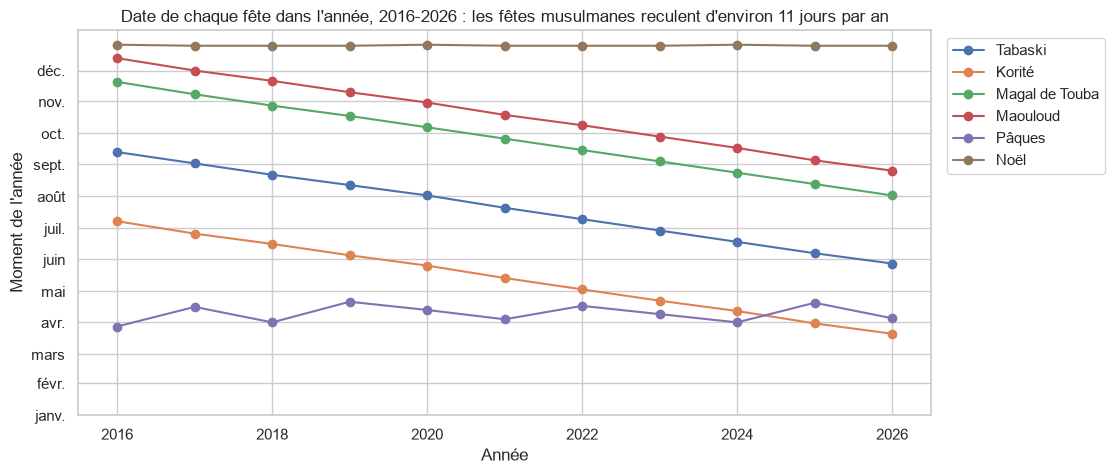

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
for evenement in ["Tabaski", "Korité", "Magal de Touba", "Maouloud", "Pâques", "Noël"]:
    occ = calendrier[(calendrier["evenement"] == evenement) & (calendrier["annee"] >= 2016)]
    ax.plot(occ["annee"], occ["date_debut"].dt.dayofyear, marker="o", label=evenement)

# Axe vertical gradué en mois plutôt qu'en numéro de jour
debuts_mois = pd.date_range("2021-01-01", periods=12, freq="MS")
ax.set_yticks(debuts_mois.dayofyear)
ax.set_yticklabels(["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."])
ax.set_title("Date de chaque fête dans l'année, 2016-2026 : les fêtes musulmanes reculent d'environ 11 jours par an")
ax.set_xlabel("Année")
ax.set_ylabel("Moment de l'année")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
sauver_figure(fig, "p2_dates_fetes_par_annee")
plt.show()

le pic de ventes de moutons change de mois

Figure enregistrée : p2_ventes_mouton_mois_annee.png


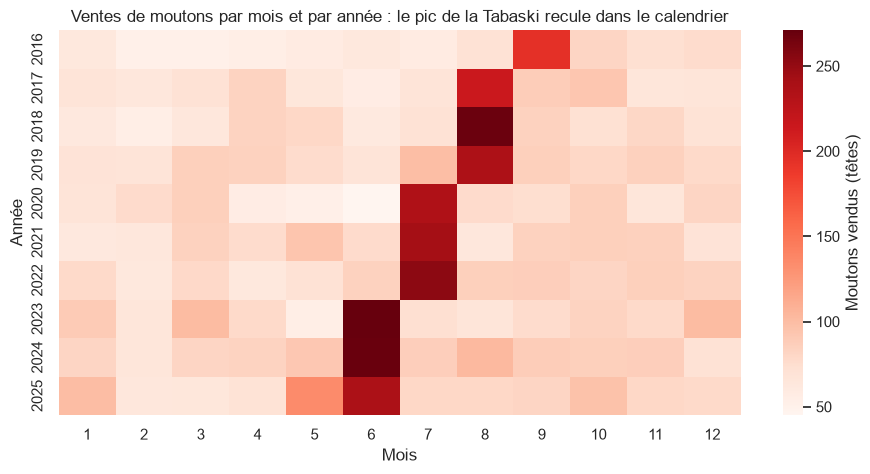

Mois du pic de ventes de moutons : {2016: 9, 2017: 8, 2018: 8, 2019: 8, 2020: 7, 2021: 7, 2022: 7, 2023: 6, 2024: 6, 2025: 6}


In [16]:
mouton = ventes[ventes["categorie"] == "betail_mouton"]
mouton_mois = (mouton.groupby([mouton["date"].dt.year.rename("annee"), mouton["date"].dt.month.rename("mois")])
               ["quantite"].sum().unstack())

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(mouton_mois, cmap="Reds", ax=ax, cbar_kws={"label": "Moutons vendus (têtes)"})
ax.set_title("Ventes de moutons par mois et par année : le pic de la Tabaski recule dans le calendrier")
ax.set_xlabel("Mois")
ax.set_ylabel("Année")
sauver_figure(fig, "p2_ventes_mouton_mois_annee")
plt.show()

# Mois du pic chaque année
print("Mois du pic de ventes de moutons :", mouton_mois.idxmax(axis=1).to_dict())

In [17]:
### 2.3 Ajout des variables d'événement aux ventes

fusion et sauvegarde

In [18]:
if peut_recharger(chemin_parquet("ventes_evenements")):
    ventes_evt = pd.read_parquet(chemin_parquet("ventes_evenements"))
    print("Ventes + variables d'événement rechargées")
else:
    # Une ligne de vente reçoit les variables de sa date (plusieurs ventes pour une même date)
    ventes_evt = ventes.merge(vars_calendrier, on="date", how="left", validate="many_to_one")
    ventes_evt.to_parquet(chemin_parquet("ventes_evenements"), index=False)
    print("Ventes + variables d'événement calculées et sauvegardées")

print("Dimensions :", ventes_evt.shape)
print("Valeurs manquantes après fusion :", int(ventes_evt.isna().sum().sum()))
print("Mémoire :", round(ventes_evt.memory_usage(deep=True).sum() / 1e6, 1), "Mo")

Ventes + variables d'événement calculées et sauvegardées
Dimensions : (530490, 28)
Valeurs manquantes après fusion : 0
Mémoire : 43.0 Mo


### Conclusion de la partie 2

La fonction `variables_calendrier` produit 19 variables pour chaque date : `av_` et `ap_` pour 9 fêtes, plafonnées à 60 jours, et l'indicateur `ramadan`, qui compte 29 ou 30 jours par an. Elle utilise `pd.merge_asof` vers l'avant et vers l'arrière sur les 4 018 dates de 2016-2026, sans boucle sur les ventes. Le résultat est ensuite fusionné aux 530 490 lignes de ventes (28 colonnes, aucune valeur manquante). Le plafond traite aussi les bords du calendrier : il n'y a pas d'occurrence précédente début 2016 ni d'occurrence suivante fin 2026. Selon le calendrier, **la Tabaski recule de 10 à 12 jours chaque année** (10,7 en moyenne, soit 354-355 jours entre deux Tabaski) : elle passe du 12 septembre 2016 au 28 mai 2026, soit 108 jours plus tôt. Le pic de ventes de moutons suit ce recul : septembre en 2016, août en 2017-2019, juillet en 2020-2022, juin en 2023-2025. **Une variable « mois » ne suffit donc pas** : apprise sur 2016-2023, elle associerait l'effet de la Tabaski à juillet-août, alors qu'en 2025 il tombe en juin. Elle coupe aussi une fenêtre d'achat entre deux mois, comme en 2025, où une partie des achats tombe fin mai. Seule la distance en jours à la fête, recalculée chaque année depuis le calendrier, suit ce déplacement. Les fêtes chrétiennes ne bougent pas de la même façon : Noël est fixe, et Pâques varie entre fin mars et fin avril.

## Partie 3 · Mesurer l'effet des fêtes

### 3.1 Uplift par fête et top 3 national
Fenêtre d'achat : J-7 à J-1. Référence : J-60 à J-31. Pour le Ramadan, J0 = premier jour du jeûne.

fonctions d’uplift

In [19]:
FENETRE = (1, 7)        # J-7 à J-1
REFERENCE = (31, 60)    # J-60 à J-31
PERIODE_VENTES = ("2016-01-01", "2025-12-31")
VILLES = magasins.set_index("magasin_id")["ville"]


def periodes_fete(evenement, fenetre=FENETRE, reference=REFERENCE):
    """Dates de la fenêtre d'achat et de la référence pour chaque occurrence d'une fête entre 2016 et 2025."""
    j0s = calendrier.loc[(calendrier["evenement"] == evenement)
                         & calendrier["date_debut"].between(*PERIODE_VENTES), "date_debut"]
    morceaux = []
    for j0 in j0s:   # une dizaine d'occurrences par fête (boucle sur le calendrier, pas sur les ventes)
        for periode, (debut, fin) in [("fenetre", fenetre), ("reference", reference)]:
            jours = pd.date_range(j0 - pd.Timedelta(days=fin), j0 - pd.Timedelta(days=debut), freq="D")
            morceaux.append(pd.DataFrame({"date": jours, "j0": j0, "periode": periode}))
    return pd.concat(morceaux, ignore_index=True)


def calcul_uplift(ventes, evenement, par=("categorie",), periodes=None):
    """Uplift = vente moyenne par jour dans la fenêtre / vente moyenne par jour dans la référence.
    Moyennes calculées par magasin x catégorie x occurrence, puis additionnées selon `par`,
    en ne gardant que les magasins présents dans les deux périodes.
    `periodes` : par défaut J-7..J-1 contre J-60..J-31 ; on peut fournir d'autres périodes."""
    if periodes is None:
        periodes = periodes_fete(evenement)
    periodes = periodes.copy()
    periodes["date"] = periodes["date"].astype(ventes["date"].dtype)   # même type de date que les ventes
    v = ventes[["date", "magasin_id", "categorie", "quantite"]].merge(periodes, on="date")
    moyennes = (v.groupby(["magasin_id", "categorie", "j0", "periode"], observed=True)["quantite"]
                .mean().unstack("periode")
                .dropna())                     # magasin absent d'une des deux périodes -> exclu
    resultat = moyennes.groupby(level=list(par), observed=True)[["fenetre", "reference"]].sum()
    resultat["uplift"] = (resultat["fenetre"] / resultat["reference"]).replace(np.inf, np.nan)
    resultat.insert(0, "evenement", evenement)
    return resultat.reset_index()

uplift national et top 3

In [20]:
if peut_recharger(chemin_parquet("uplift_national")):
    uplift_national = pd.read_parquet(chemin_parquet("uplift_national"))
else:
    uplift_national = pd.concat([calcul_uplift(ventes, f) for f in FETES], ignore_index=True)
    uplift_national.to_parquet(chemin_parquet("uplift_national"), index=False)

# Trois catégories les plus touchées par chaque fête
top3 = (uplift_national.sort_values("uplift", ascending=False)
        .groupby("evenement", sort=False).head(3).copy())
top3["rang"] = top3.groupby("evenement").cumcount() + 1
top3["texte"] = top3["categorie"].astype(str) + " (x" + top3["uplift"].round(2).astype(str) + ")"
tableau_top3 = top3.pivot(index="evenement", columns="rang", values="texte").reindex(list(FETES))
tableau_top3.columns = ["1re catégorie", "2e catégorie", "3e catégorie"]
tableau_top3

,1re catégorie,2e catégorie,3e catégorie
evenement,,,
Ramadan,betail_mouton (x1.0),huile (x0.99),sucre (x0.99)
Korité,dattes (x4.09),tissus_habillement (x2.48),beaute_coiffure (x2.32)
Tabaski,betail_mouton (x10.4),oignons (x2.76),tissus_habillement (x2.5)
Tamkharit,cereales_mil (x1.71),volaille (x1.4),lait (x1.19)
Magal de Touba,credit_mobile (x1.43),riz (x1.32),boissons (x1.32)
Maouloud,boissons (x1.21),sucre (x1.18),riz (x1.16)
Pâques,arachide_bouye (x1.8),dattes (x1.56),boissons (x1.35)
Pèlerinage de Popenguine,betail_mouton (x2.02),oignons (x1.16),credit_mobile (x1.06)
Noël,jouets_cadeaux (x3.95),volaille (x1.84),boissons (x1.64)


carte de chaleur événement × catégorie

Figure enregistrée : p3_carte_chaleur_uplift.png


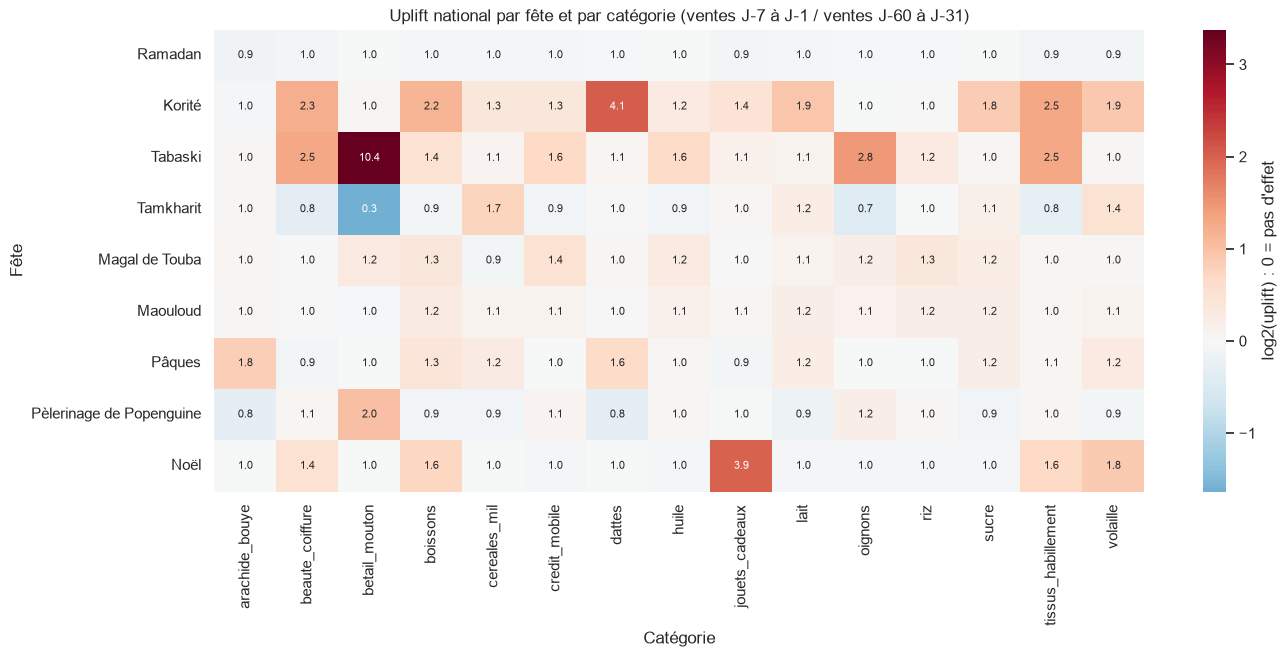

In [21]:
carte = uplift_national.pivot(index="evenement", columns="categorie", values="uplift").reindex(list(FETES))

fig, ax = plt.subplots(figsize=(15, 6))
# Couleur sur une échelle log2 (1 = pas d'effet, x2 et /2 à égale distance), valeurs réelles affichées
sns.heatmap(np.log2(carte), annot=carte, fmt=".1f", cmap="RdBu_r", center=0, ax=ax,
            annot_kws={"size": 8}, cbar_kws={"label": "log2(uplift) : 0 = pas d'effet"})
ax.set_title("Uplift national par fête et par catégorie (ventes J-7 à J-1 / ventes J-60 à J-31)")
ax.set_xlabel("Catégorie")
ax.set_ylabel("Fête")
sauver_figure(fig, "p3_carte_chaleur_uplift")
plt.show()

3.2 Magal et Maouloud par point de vente

Magal et Maouloud par magasin

Figure enregistrée : p3_magal_maouloud_par_magasin.png


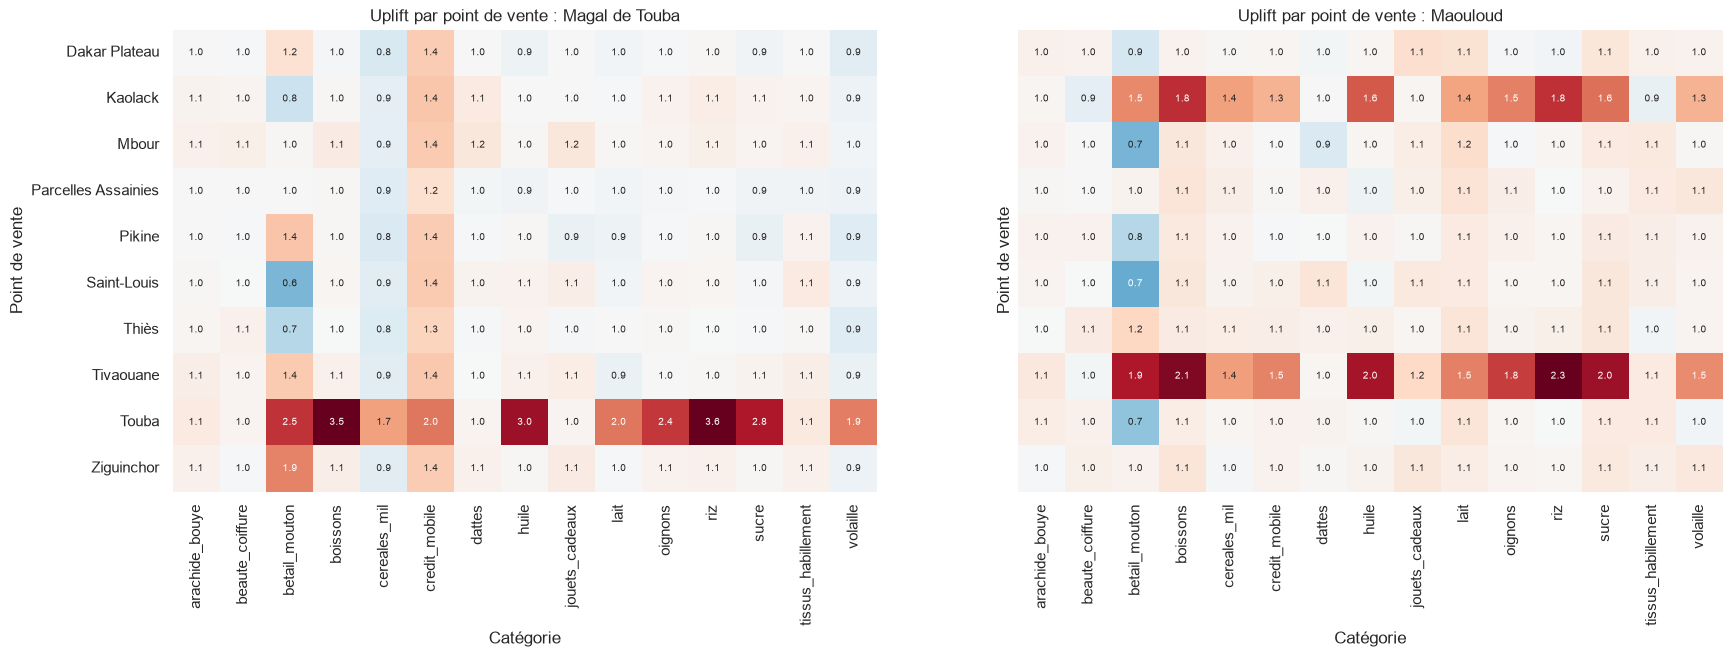

uplift_median                                               top3
evenement      ville                                                                                
Magal de Touba Dakar Plateau                 0.99   credit_mobile x1.4, betail_mouton x1.2, riz x1.0
               Kaolack                       1.03          credit_mobile x1.4, dattes x1.1, riz x1.1
               Parcelles Assainies           0.98  credit_mobile x1.2, boissons x1.0, arachide_bo...
               Pikine                        0.99  betail_mouton x1.4, credit_mobile x1.4, tissus...
               Tivaouane                     1.05  credit_mobile x1.4, betail_mouton x1.4, jouets...
               Touba                         1.97                riz x3.6, boissons x3.5, huile x3.0
Maouloud       Dakar Plateau                 1.03         jouets_cadeaux x1.1, lait x1.1, sucre x1.1
               Kaolack                       1.38                boissons x1.8, riz x1.8, huile x1.6
               Parcelles Assainies           1.04            lait x1.1, boissons x1.1, volaille x1.1
               Pikine                        1.04               boissons x1.1, lait x1.1, sucre x1.1
               Tivaouane                     1.50                riz x2.3, boissons x2.1, sucre x2.0
               Touba                         1.03     lait x1.1, tissus_habillement x1.1, sucre x1.1

In [22]:
if peut_recharger(chemin_parquet("uplift_magasin")):
    uplift_magasin = pd.read_parquet(chemin_parquet("uplift_magasin"))
else:
    uplift_magasin = pd.concat([calcul_uplift(ventes, f, par=("magasin_id", "categorie"))
                                for f in ["Magal de Touba", "Maouloud"]], ignore_index=True)
    uplift_magasin["ville"] = uplift_magasin["magasin_id"].astype(str).map(VILLES)
    uplift_magasin.to_parquet(chemin_parquet("uplift_magasin"), index=False)

# Les deux cartes côte à côte : magasin (ville) x catégorie
fig, axes = plt.subplots(1, 2, figsize=(20, 6), sharey=True)
for ax, fete in zip(axes, ["Magal de Touba", "Maouloud"]):
    c = (uplift_magasin[uplift_magasin["evenement"] == fete]
         .pivot(index="ville", columns="categorie", values="uplift"))
    sns.heatmap(np.log2(c), annot=c, fmt=".1f", cmap="RdBu_r", center=0, ax=ax,
                annot_kws={"size": 7}, cbar=False)
    ax.set_title(f"Uplift par point de vente : {fete}")
    ax.set_xlabel("Catégorie")
    ax.set_ylabel("Point de vente")
sauver_figure(fig, "p3_magal_maouloud_par_magasin")
plt.show()


# Résumé pour Touba, Tivaouane, Kaolack et les trois magasins de Dakar
def top_texte(groupe, n=3):
    """Les n catégories au plus fort uplift, sous forme de texte."""
    g = groupe.nlargest(n, "uplift")
    return ", ".join(f"{c} x{u:.1f}" for c, u in zip(g["categorie"].astype(str), g["uplift"]))


focus = uplift_magasin[uplift_magasin["magasin_id"].astype(str).isin(["M05", "M06", "M07", "M01", "M02", "M03"])]
resume_villes = (focus.groupby(["evenement", "ville"])
                 .agg(uplift_median=("uplift", "median"))
                 .join(focus.groupby(["evenement", "ville"]).apply(top_texte).rename("top3"))
                 .round(2))
resume_villes

### 3.3 Chevauchements d'événements

repérage des chevauchements dans le calendrier

In [23]:
occ = calendrier[calendrier["date_debut"].between(*PERIODE_VENTES)][["evenement", "date_debut", "date_fin"]]
lignes_chev = []
for a in occ.itertuples():   # ~90 occurrences : boucle sur le calendrier, pas sur les ventes
    fen_a = (a.date_debut - pd.Timedelta(days=7), a.date_debut - pd.Timedelta(days=1))
    ref_a = (a.date_debut - pd.Timedelta(days=60), a.date_debut - pd.Timedelta(days=31))
    for b in occ.itertuples():
        if b.evenement == a.evenement:
            continue
        # Période d'achat de l'autre fête : J-7 jusqu'à J0 (et tout le mois pour le Ramadan)
        achat_b = (b.date_debut - pd.Timedelta(days=7), b.date_fin)
        for nom, (debut, fin) in [("fenêtre", fen_a), ("référence", ref_a)]:
            if max(debut, achat_b[0]) <= min(fin, achat_b[1]):     # les deux intervalles se touchent
                lignes_chev.append({"fete": a.evenement, "annee": a.date_debut.year,
                                    "periode_touchee": nom, "autre_fete": b.evenement})

chevauchements = pd.DataFrame(lignes_chev)
(chevauchements.groupby(["fete", "periode_touchee", "autre_fete"])["annee"]
 .apply(lambda s: sorted(s.tolist())).rename("annees").reset_index())

,fete,periode_touchee,autre_fete,annees
0,Korité,fenêtre,Pèlerinage de Popenguine,[2019]
1,Korité,fenêtre,Ramadan,"[2016, 2017, 2018, 2019, 2020, 2021, 2022, 202..."
2,Korité,référence,Pâques,"[2019, 2020, 2021]"
3,Korité,référence,Pèlerinage de Popenguine,"[2016, 2018]"
4,Korité,référence,Ramadan,"[2016, 2017, 2018, 2019, 2020, 2021, 2022, 202..."
5,Magal de Touba,référence,Tamkharit,"[2016, 2017, 2018, 2019, 2020, 2021, 2022, 202..."
6,Maouloud,référence,Magal de Touba,"[2018, 2020, 2022, 2023, 2024]"
7,Noël,référence,Magal de Touba,"[2016, 2017, 2018]"
8,Noël,référence,Maouloud,"[2017, 2018, 2019, 2020]"
9,Pâques,fenêtre,Ramadan,"[2022, 2023, 2024]"


deux exemples chiffrés

In [24]:
# Exemple 1 : Pâques, uplift par année pour les produits du Ramadan et du ngalakh
paques = calcul_uplift(ventes, "Pâques", par=("categorie", "j0"))
paques["annee"] = paques["j0"].dt.year
produits = ["dattes", "sucre", "lait", "arachide_bouye", "cereales_mil"]
display(paques[paques["categorie"].isin(produits)]
        .pivot(index="categorie", columns="annee", values="uplift").round(2))
for periode in ["fenêtre", "référence"]:
    annees = chevauchements.query("fete == 'Pâques' and autre_fete == 'Ramadan' and periode_touchee == @periode")["annee"]
    print(f"Années où le Ramadan touche la {periode} de Pâques :", sorted(annees.tolist()))

# Exemple 2 : Tamkharit, uplift par année pour les produits de la Tabaski
tamkharit = calcul_uplift(ventes, "Tamkharit", par=("categorie", "j0"))
tamkharit["annee"] = tamkharit["j0"].dt.year
display(tamkharit[tamkharit["categorie"].isin(["betail_mouton", "oignons", "tissus_habillement", "cereales_mil"])]
        .pivot(index="categorie", columns="annee", values="uplift").round(2))

# Complément 1 : uplift PENDANT le Ramadan (tout le mois) rapporté à la même référence J-60 à J-31
morceaux = []
for r in calendrier[(calendrier["evenement"] == "Ramadan")
                    & calendrier["date_debut"].between(*PERIODE_VENTES)].itertuples():
    morceaux.append(pd.DataFrame({"date": pd.date_range(r.date_debut, r.date_fin),
                                  "j0": r.date_debut, "periode": "fenetre"}))
    morceaux.append(pd.DataFrame({"date": pd.date_range(r.date_debut - pd.Timedelta(days=60),
                                                        r.date_debut - pd.Timedelta(days=31)),
                                  "j0": r.date_debut, "periode": "reference"}))
uplift_pendant_ramadan = calcul_uplift(ventes, "Ramadan (pendant le mois)", periodes=pd.concat(morceaux))
print("Uplift pendant le Ramadan, top 5 :")
display(uplift_pendant_ramadan.nlargest(5, "uplift")[["categorie", "uplift"]].round(2))

# Complément 2 : Popenguine par année, pour voir si le mouton x2 vient de la Tabaski 2025
popenguine = calcul_uplift(ventes, "Pèlerinage de Popenguine", par=("categorie", "j0"))
popenguine["annee"] = popenguine["j0"].dt.year
display(popenguine[popenguine["categorie"].isin(["betail_mouton", "oignons", "tissus_habillement"])]
        .pivot(index="categorie", columns="annee", values="uplift").round(2))

annee,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
categorie,,,,,,,,,,
arachide_bouye,1.87,1.79,1.84,1.73,1.57,1.87,1.75,1.88,1.81,1.91
cereales_mil,1.12,1.12,1.23,1.13,1.03,1.14,1.46,1.45,1.47,0.97
dattes,1.03,1.00,0.92,0.93,0.86,1.07,3.79,3.82,3.83,0.34
lait,1.04,1.04,1.01,1.00,0.83,0.98,1.89,1.92,1.91,0.63
sucre,0.98,0.98,0.96,0.97,1.04,0.99,1.77,1.87,1.78,0.60


Années où le Ramadan touche la fenêtre de Pâques : [2022, 2023, 2024]
Années où le Ramadan touche la référence de Pâques : [2025]


annee,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
categorie,,,,,,,,,,
betail_mouton,0.47,0.28,0.29,0.39,0.40,0.42,0.30,0.23,0.19,0.34
cereales_mil,1.68,1.66,1.64,1.67,1.71,1.72,1.77,1.74,1.65,1.84
oignons,0.72,0.78,0.73,0.74,0.73,0.81,0.74,0.74,0.70,0.78
tissus_habillement,1.10,0.80,0.74,0.78,0.81,0.83,0.76,0.77,0.77,0.80


Uplift pendant le Ramadan, top 5 :


periode,categorie,uplift
6,dattes,3.94
9,lait,1.87
12,sucre,1.80
3,boissons,1.66
13,tissus_habillement,1.30


annee,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
categorie,,,,,,,,,,
betail_mouton,1.58,0.96,1.43,1.26,0.50,1.26,2.22,0.91,1.08,9.79
oignons,1.04,1.03,1.05,0.97,0.93,1.01,1.03,1.01,1.04,2.27
tissus_habillement,1.01,1.03,0.95,1.57,1.06,0.91,0.67,0.72,0.77,2.04


### 3.4 Évolution sur dix ans : chiffre d'affaires nominal et réel, prix du mouton, paiement mobile

indice de prix et évolution

In [25]:
annee = ventes["date"].dt.year.rename("annee")

# Indice des prix : somme des poids 2016 x (prix médian de l'année / prix médian 2016)
prix_median = ventes.groupby([annee, "categorie"], observed=True)["prix_unitaire_fcfa"].median().unstack()
ca_2016 = ventes[annee == 2016].groupby("categorie", observed=True)["chiffre_affaires_fcfa"].sum()
poids_2016 = ca_2016 / ca_2016.sum()
indice_prix = (prix_median.div(prix_median.loc[2016], axis=1) * poids_2016).sum(axis=1)

# Périmètre constant : les 8 magasins ouverts dès 2016
perimetre = ventes["magasin_id"].astype(str).isin(magasins.loc[magasins["date_ouverture"] <= "2016-01-01", "magasin_id"])

evolution = pd.DataFrame({
    "ca_nominal": ventes.groupby(annee)["chiffre_affaires_fcfa"].sum(),
    "indice_prix": indice_prix,
    "ca_nominal_8_magasins": ventes[perimetre].groupby(annee[perimetre])["chiffre_affaires_fcfa"].sum(),
})
evolution["ca_reel"] = evolution["ca_nominal"] / evolution["indice_prix"]
evolution["ca_reel_8_magasins"] = evolution["ca_nominal_8_magasins"] / evolution["indice_prix"]
# Part du paiement mobile pondérée par le chiffre d'affaires
evolution["part_mobile"] = ((ventes["part_paiement_mobile"] * ventes["chiffre_affaires_fcfa"]).groupby(annee).sum()
                            / evolution["ca_nominal"])

# Prix du mouton : médiane dans la fenêtre J-7 à J-1 de la Tabaski contre la référence J-60 à J-31
per_tab = periodes_fete("Tabaski")
per_tab["date"] = per_tab["date"].astype(ventes["date"].dtype)
mouton_tab = ventes[ventes["categorie"] == "betail_mouton"].merge(per_tab, on="date")
prix_mouton = (mouton_tab.groupby([mouton_tab["j0"].dt.year.rename("annee"), "periode"])
               ["prix_unitaire_fcfa"].median().unstack())
prix_mouton["surprime_pct"] = 100 * (prix_mouton["fenetre"] / prix_mouton["reference"] - 1)
evolution = evolution.join(prix_mouton.add_prefix("prix_mouton_"))
evolution.to_parquet(chemin_parquet("evolution_dix_ans"))

display(evolution.assign(**{c: evolution[c] / 1e9 for c in evolution.columns if c.startswith("ca_")}).round(3))
print("(chiffres d'affaires en milliards de FCFA)")

,ca_nominal,indice_prix,ca_nominal_8_magasins,ca_reel,ca_reel_8_magasins,part_mobile,prix_mouton_fenetre,prix_mouton_reference,prix_mouton_surprime_pct
annee,,,,,,,,,
2016,4.477,1.000,4.477,4.477,4.477,0.031,101000.0,92000.0,9.783
2017,4.949,1.007,4.611,4.914,4.580,0.036,106500.0,97000.0,9.794
2018,5.402,1.016,4.735,5.315,4.659,0.043,112000.0,100500.0,11.443
2019,5.577,1.018,4.838,5.477,4.751,0.053,116250.0,104500.0,11.244
2020,5.540,1.052,4.810,5.264,4.570,0.067,123000.0,112000.0,9.821
2021,6.078,1.077,5.274,5.643,4.896,0.096,129750.0,119000.0,9.034
2022,7.020,1.209,6.089,5.809,5.039,0.155,148500.0,135500.0,9.594
2023,7.535,1.279,6.537,5.893,5.112,0.240,163500.0,147500.0,10.847
2024,7.796,1.291,6.766,6.037,5.240,0.352,172000.0,155000.0,10.968


(chiffres d'affaires en milliards de FCFA)


figure des trois évolutions

Figure enregistrée : p3_evolution_dix_ans.png


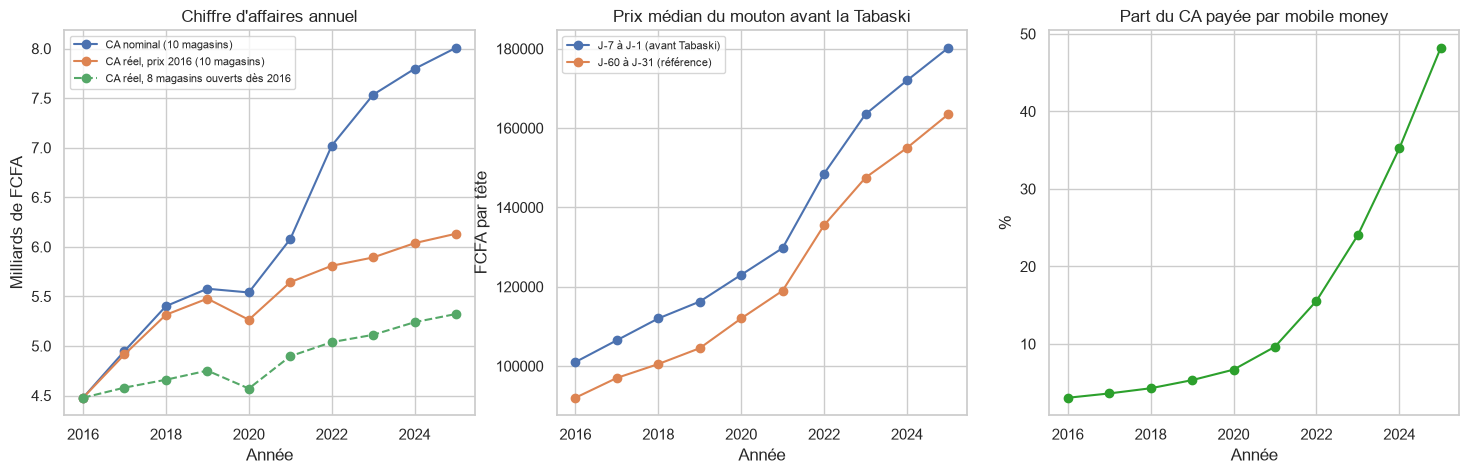

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(evolution.index, evolution["ca_nominal"] / 1e9, marker="o", label="CA nominal (10 magasins)")
axes[0].plot(evolution.index, evolution["ca_reel"] / 1e9, marker="o", label="CA réel, prix 2016 (10 magasins)")
axes[0].plot(evolution.index, evolution["ca_reel_8_magasins"] / 1e9, marker="o", linestyle="--",
             label="CA réel, 8 magasins ouverts dès 2016")
axes[0].set(title="Chiffre d'affaires annuel", xlabel="Année", ylabel="Milliards de FCFA")
axes[0].legend(fontsize=8)

axes[1].plot(evolution.index, evolution["prix_mouton_fenetre"], marker="o", label="J-7 à J-1 (avant Tabaski)")
axes[1].plot(evolution.index, evolution["prix_mouton_reference"], marker="o", label="J-60 à J-31 (référence)")
axes[1].set(title="Prix médian du mouton avant la Tabaski", xlabel="Année", ylabel="FCFA par tête")
axes[1].legend(fontsize=8)

axes[2].plot(evolution.index, 100 * evolution["part_mobile"], marker="o", color="tab:green")
axes[2].set(title="Part du CA payée par mobile money", xlabel="Année", ylabel="%")

sauver_figure(fig, "p3_evolution_dix_ans")
plt.show()

### Conclusion de la partie 3

Avec la même fenêtre (J-7 à J-1) et la même référence (J-60 à J-31) pour toutes les fêtes, les effets nationaux les plus forts sont ceux de la **Tabaski** (mouton ×10,4, oignons ×2,8, habillement ×2,5), de la **Korité** (dattes ×4,1, habillement ×2,5, beauté-coiffure ×2,3) et de **Noël** (jouets ×4,0, volaille ×1,8, boissons ×1,6). Pâques fait monter l'arachide (×1,8, pour le ngalakh) et la Tamkharit les céréales de mil (×1,7).

Le **Ramadan** ne montre aucun achat d'anticipation (uplift ≈ 1 avant son début) : son effet se produit pendant le mois, avec les dattes à ×3,9, le lait à ×1,9 et le sucre à ×1,8.

Le **Magal et le Maouloud sont des effets locaux**. Presque invisibles au niveau national, ils sont nets à Touba pour le Magal (médiane ×2,0 ; riz ×3,6, boissons ×3,5, huile ×3,0), et à Tivaouane (×1,5) et Kaolack (×1,4) pour le Maouloud. Dakar reste proche de 1.

Les **chevauchements faussent plusieurs uplifts** :
- Les dattes montent à ×3,8 à Pâques en 2022-2024, quand Pâques tombe pendant le Ramadan, contre environ 1 les autres années. Elles tombent à ×0,34 en 2025, quand c'est la référence qui est dans le Ramadan.
- La référence de la Tamkharit contient chaque année les achats de la Tabaski : le mouton y paraît artificiellement à ×0,2-0,5.
- Le mouton ×2,0 de Popenguine vient uniquement de 2025 (×9,8), l'année où la Tabaski tombe deux jours avant le pèlerinage.

**Sur dix ans**, le CA nominal passe de 4,48 à 8,01 milliards de FCFA (+79 %), mais l'indice des prix atteint 1,31 en 2025. En réel, la hausse n'est donc que de +37 %, et de +19 % à périmètre constant (les 8 magasins ouverts dès 2016). Le prix médian du mouton juste avant la Tabaski passe de 101 000 à 180 250 FCFA, avec une surprime stable de 9 à 11 % par rapport à la référence. Enfin, la part du paiement mobile passe de 3,1 % à 48,2 % du CA.

## Bonus · Effet propre des promotions et biais de confusion

les promotions sont-elles plus fréquentes avant les fêtes ?

In [27]:
# Contexte de chaque jour : fenêtre J-7 à J-1 d'une fête, mois de Ramadan, ou hors fête
noms_fetes = list(FETES.values())
conditions = [ventes_evt[f"av_{n}"].between(1, 7) for n in noms_fetes] + [ventes_evt["ramadan"] == 1]
ventes_evt["contexte"] = np.select(conditions, [f"avant_{n}" for n in noms_fetes] + ["pendant_ramadan"],
                                   default="hors_fete")
ventes_evt["annee"] = ventes_evt["date"].dt.year

freq_promo = (ventes_evt.groupby("contexte")["promo"].mean().mul(100).round(1)
              .sort_values(ascending=False).rename("pct_jours_en_promo"))
print("Part des lignes en promotion selon le contexte (%) :")
display(freq_promo.to_frame())

Part des lignes en promotion selon le contexte (%) :


,pct_jours_en_promo
contexte,
avant_korite,7.4
avant_tabaski,7.4
pendant_ramadan,7.4
avant_noel,7.2
avant_magal,6.6
avant_paques,6.4
avant_maouloud,5.5
avant_tamkharit,5.5
avant_popenguine,5.1


effet naïf contre effet ajusté

In [28]:
# 1) Effet naïf : vente moyenne avec promo / sans promo, toutes périodes mélangées
naif = ventes_evt.groupby(["categorie", "promo"], observed=True)["quantite"].mean().unstack()
naif["effet_naif"] = naif[1] / naif[0]

# 2) Effet ajusté : même rapport, mais à l'intérieur de strates comparables
STRATES = ["magasin_id", "categorie", "annee", "contexte"]
strates = (ventes_evt.groupby(STRATES + ["promo"], observed=True)["quantite"]
           .agg(["mean", "size"]).unstack("promo"))
strates.columns = [f"{stat}_{p}" for stat, p in strates.columns]      # mean_0, mean_1, size_0, size_1
strates = strates.dropna(subset=["mean_0", "mean_1"]).reset_index()   # strates avec ET sans promo
# Pondération par le nombre de jours de promotion : effet moyen sur les jours où il y a une promo
strates["num"] = strates["mean_1"] * strates["size_1"]
strates["den"] = strates["mean_0"] * strates["size_1"]
ajuste = strates.groupby("categorie", observed=True)[["num", "den"]].sum()
ajuste["effet_ajuste"] = ajuste["num"] / ajuste["den"]

effet_promo = naif[["effet_naif"]].join(ajuste["effet_ajuste"]).round(2)
effet_promo["biais_pct"] = (100 * (effet_promo["effet_naif"] / effet_promo["effet_ajuste"] - 1)).round(1)
display(effet_promo.sort_values("effet_naif", ascending=False))

part_couverte = strates["size_1"].sum() / (ventes_evt["promo"] == 1).sum()
print(f"Jours de promotion couverts par une strate comparable : {100 * part_couverte:.1f} %")
print("Effet global naïf  :", round(ventes_evt.loc[ventes_evt["promo"] == 1, "quantite"].mean()
                                    / ventes_evt.loc[ventes_evt["promo"] == 0, "quantite"].mean(), 2))
print("Effet global ajusté :", round(strates["num"].sum() / strates["den"].sum(), 2))
effet_promo.to_parquet(chemin_parquet("effet_promo"))

,effet_naif,effet_ajuste,biais_pct
categorie,,,
dattes,1.56,1.29,20.9
betail_mouton,1.49,1.33,12.0
beaute_coiffure,1.47,1.34,9.7
boissons,1.46,1.34,9.0
tissus_habillement,1.45,1.33,9.0
sucre,1.44,1.31,9.9
volaille,1.42,1.31,8.4
lait,1.41,1.29,9.3
jouets_cadeaux,1.40,1.30,7.7


Jours de promotion couverts par une strate comparable : 100.0 %
Effet global naïf  : 1.41
Effet global ajusté : 1.31


graphique

Figure enregistrée : bonus_effet_promotions.png


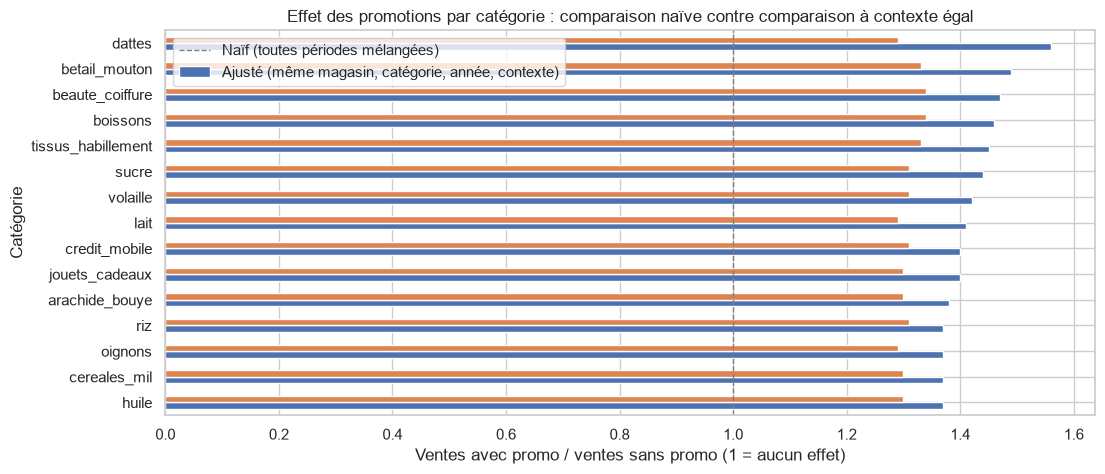

In [29]:
fig, ax = plt.subplots(figsize=(12, 5))
effet_promo.sort_values("effet_naif")[["effet_naif", "effet_ajuste"]].plot.barh(ax=ax)
ax.axvline(1, color="grey", linestyle="--", linewidth=1)
ax.set_title("Effet des promotions par catégorie : comparaison naïve contre comparaison à contexte égal")
ax.set_xlabel("Ventes avec promo / ventes sans promo (1 = aucun effet)")
ax.set_ylabel("Catégorie")
ax.legend(["Naïf (toutes périodes mélangées)", "Ajusté (même magasin, catégorie, année, contexte)"])
sauver_figure(fig, "bonus_effet_promotions")
plt.show()

### Conclusion du bonus promotions

Les promotions sont environ **deux fois plus fréquentes** avant les fêtes et pendant le Ramadan (5,1 à 7,4 % des lignes) qu'en dehors des fêtes (3,7 %). Comparer simplement les jours avec et sans promotion mélange donc deux effets : la fête augmente à la fois les ventes et la probabilité d'une promotion. La fête est une **variable de confusion**. La comparaison naïve donne ainsi un effet de **×1,41** (jusqu'à ×1,56 pour les dattes). À contexte égal, c'est-à-dire même magasin, même catégorie, même année et même période de fête, l'**effet propre tombe à ×1,31**, très homogène entre catégories (×1,29 à ×1,34). Toutes les lignes en promotion ont trouvé une strate de comparaison. Le biais naïf est le plus fort là où les promotions se concentrent dans les périodes de forte demande : dattes (+21 %, Ramadan) et mouton (+12 %, Tabaski). Une limite subsiste : à l'intérieur d'une même fenêtre, les jours de promotion peuvent être plus proches de J0, ce qui laisserait un petit biais résiduel.

## Partie 4 · Prévoir la demande un an à l'avance

### 4.1 Préparation : variables connues un an à l'avance, découpage temporel, WAPE
Entraînement 2016-2023, validation 2024, test 2025 (une seule fois, en 4.5). Variables : calendrier, point de vente, catégorie, promotions planifiées. Aucune vente passée.

préparation

In [30]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
import time

COLS_AV = [f"av_{n}" for n in FETES.values()]
PRIORITE_FETES = ["tabaski", "korite", "noel", "paques", "magal", "maouloud", "tamkharit", "popenguine"]


def contexte_evenement(X):
    """Tranche d'événement de chaque jour (une seule par jour, par ordre de priorité des fêtes)."""
    conditions, noms = [], []
    for n in PRIORITE_FETES:
        conditions += [X[f"av_{n}"] == 0, X[f"av_{n}"].between(1, 3), X[f"av_{n}"].between(4, 7), X[f"ap_{n}"].between(1, 3)]
        noms += [f"{n}_J0", f"{n}_J-3_J-1", f"{n}_J-7_J-4", f"{n}_J+1_J+3"]
    conditions.append(X["ramadan"] == 1)
    noms.append("pendant_ramadan")
    return pd.Series(np.select(conditions, noms, default="hors_fete"), index=X.index)


def preparer_features(df):
    """Variables connues un an à l'avance pour un DataFrame (date, magasin_id, categorie, promo [, quantite])."""
    colonnes = ["date", "magasin_id", "categorie", "promo"] + [c for c in ["quantite", "quantite_imputee"] if c in df]
    X = df[colonnes].merge(vars_calendrier, on="date", how="left")
    X["annee"] = X["date"].dt.year
    X["mois"] = X["date"].dt.month
    X["jour_semaine"] = X["date"].dt.dayofweek
    X["contexte"] = contexte_evenement(X)
    # Croisements pour la Ridge (le HGB trouve seul ces interactions)
    X["mag_cat"] = (X["magasin_id"].astype(str) + "|" + X["categorie"].astype(str)).astype("category")
    X["cat_contexte"] = (X["categorie"].astype(str) + "|" + X["contexte"]).astype("category")
    X["mag_contexte"] = (X["magasin_id"].astype(str) + "|" + X["contexte"]).astype("category")
    # Fenêtre d'évaluation : les 14 jours avant l'une des 9 fêtes
    X["fenetre_14j"] = (X[COLS_AV].ge(1) & X[COLS_AV].le(14)).any(axis=1)
    return X


def wape(y_vrai, y_pred):
    """WAPE = somme des erreurs absolues / somme des ventes réelles."""
    y_vrai, y_pred = np.asarray(y_vrai, dtype=float), np.asarray(y_pred, dtype=float)
    return np.abs(y_vrai - y_pred).sum() / y_vrai.sum()


def evaluer(d, pred, nom):
    """WAPE sur l'année et sur les fenêtres de 14 jours avant une fête, plus biais sur le total (hors lignes imputées)."""
    y = d["quantite"].to_numpy()
    pred = np.clip(np.asarray(pred, dtype=float), 0, None)
    garde = ~d["quantite_imputee"].to_numpy()
    evt = garde & d["fenetre_14j"].to_numpy()
    return {"modele": nom,
            "wape_annee": round(wape(y[garde], pred[garde]), 4),
            "wape_fenetres_14j": round(wape(y[evt], pred[evt]), 4),
            "biais_total_pct": round(100 * (pred[garde].sum() / y[garde].sum() - 1), 2)}


if peut_recharger(chemin_parquet("donnees_modele")):
    donnees = pd.read_parquet(chemin_parquet("donnees_modele"))
else:
    donnees = preparer_features(ventes)
    donnees.to_parquet(chemin_parquet("donnees_modele"), index=False)

train = donnees[donnees["annee"] <= 2023]
valid = donnees[donnees["annee"] == 2024]
print("Entraînement :", train.shape, "| Validation :", valid.shape)
print("Lignes de validation dans une fenêtre de 14 jours :", int(valid["fenetre_14j"].sum()))
print("Contextes distincts :", donnees["contexte"].nunique())

Entraînement : (420840, 33) | Validation : (54900, 33)
Lignes de validation dans une fenêtre de 14 jours : 18450
Contextes distincts : 34


### 4.2 Références naïves (validation 2024)

références naïves

In [31]:
# Référence 1 : vente du même jour de la semaine un an plus tôt (364 jours avant), même magasin, même catégorie
decale = (donnees[CLE + ["quantite"]]
          .assign(date=lambda d: d["date"] + pd.Timedelta(days=364))
          .rename(columns={"quantite": "ref_364j"}))
# Référence 2 : moyenne de l'année précédente par magasin, catégorie et jour de la semaine
moy_prec = (donnees.groupby(["annee", "magasin_id", "categorie", "jour_semaine"], observed=True)["quantite"]
            .mean().rename("ref_moy_annee_prec").reset_index())
moy_prec["annee"] += 1   # la moyenne de 2023 sert à prévoir 2024, celle de 2024 à prévoir 2025


def ajouter_references(d):
    """Ajoute les deux prévisions naïves à un sous-ensemble des données."""
    d = d.merge(decale, on=CLE, how="left").merge(moy_prec, on=["annee", "magasin_id", "categorie", "jour_semaine"], how="left")
    print("Références manquantes :", int(d["ref_364j"].isna().sum()), "/", int(d["ref_moy_annee_prec"].isna().sum()))
    return d.fillna({"ref_364j": 0, "ref_moy_annee_prec": 0})


valid_ref = ajouter_references(valid)
resultats_valid = [
    evaluer(valid_ref, valid_ref["ref_364j"], "Naïf : même jour 364 j avant"),
    evaluer(valid_ref, valid_ref["ref_moy_annee_prec"], "Naïf : moyenne 2023 (magasin, catégorie, jour)"),
]
pd.DataFrame(resultats_valid)

Références manquantes : 0 / 0


,modele,wape_annee,wape_fenetres_14j,biais_total_pct
0,Naïf : même jour 364 j avant,0.2728,0.2726,-2.08
1,"Naïf : moyenne 2023 (magasin, catégorie, jour)",0.1994,0.2306,-2.10


### 4.3 Régression Ridge (Pipeline + ColumnTransformer, cible en log1p)

Ridge

In [32]:
CAT_RIDGE = ["magasin_id", "categorie", "mag_cat", "jour_semaine", "mois", "cat_contexte", "mag_contexte"]
NUM_RIDGE = ["annee", "promo"]


def creer_ridge(alpha=1.0):
    """Ridge sur log1p(quantité) : one-hot appris sur l'entraînement seulement, dans le Pipeline."""
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), CAT_RIDGE),
        ("num", StandardScaler(), NUM_RIDGE),
    ])
    pipe = Pipeline([("prep", prep), ("ridge", Ridge(alpha=alpha))])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)


if peut_recharger(chemin_parquet("resultats_ridge_valid")):
    resultats_ridge = pd.read_parquet(chemin_parquet("resultats_ridge_valid"))
else:
    lignes = []
    for alpha in [0.1, 1.0, 10.0]:
        debut = time.time()
        ridge = creer_ridge(alpha).fit(train, train["quantite"])
        res = evaluer(valid, ridge.predict(valid), f"Ridge alpha={alpha}")
        res["duree_s"] = round(time.time() - debut, 1)
        lignes.append(res)
    resultats_ridge = pd.DataFrame(lignes)
    resultats_ridge.to_parquet(chemin_parquet("resultats_ridge_valid"), index=False)

resultats_ridge

,modele,wape_annee,wape_fenetres_14j,biais_total_pct,duree_s
0,Ridge alpha=0.1,0.1677,0.1771,-3.76,2.7
1,Ridge alpha=1.0,0.1677,0.1771,-3.77,2.5
2,Ridge alpha=10.0,0.1678,0.1774,-3.85,2.5


### 4.4 HistGradientBoosting : choix de la perte et des variables sur la validation 2024

HGB, 4 essais

In [33]:
CAT_HGB = ["magasin_id", "categorie"]
VARS_FETES = [f"{p}_{n}" for n in FETES.values() for p in ("av", "ap")] + ["ramadan"]
NUM_BASE = ["promo", "jour_semaine", "mois", "annee"]
JEUX_VARIABLES = {"sans_fetes": NUM_BASE, "avec_fetes": NUM_BASE + VARS_FETES}


def creer_hgb(perte, variables_num, perte_quantile=None):
    """HGB dans un Pipeline. 'squared_error' : sur log1p(quantité) ; 'poisson' ou 'quantile' : sur les quantités."""
    prep = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_HGB),
        ("num", "passthrough", variables_num),
    ])
    hgb = HistGradientBoostingRegressor(
        loss=perte, quantile=perte_quantile, learning_rate=0.1, max_iter=400, max_leaf_nodes=63,
        min_samples_leaf=40, l2_regularization=1.0, categorical_features=[0, 1],   # magasin et catégorie
        early_stopping=False, random_state=RANDOM_STATE)
    pipe = Pipeline([("prep", prep), ("hgb", hgb)])
    if perte == "squared_error":
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe


if peut_recharger(chemin_parquet("resultats_hgb_valid")):
    resultats_hgb = pd.read_parquet(chemin_parquet("resultats_hgb_valid"))
else:
    lignes = []
    for perte in ["squared_error", "poisson"]:
        for nom_jeu, variables in JEUX_VARIABLES.items():
            debut = time.time()
            modele = creer_hgb(perte, variables).fit(train, train["quantite"])
            nom = f"HGB {perte}{' (log1p)' if perte == 'squared_error' else ''} | {nom_jeu}"
            res = evaluer(valid, modele.predict(valid), nom)
            res["duree_s"] = round(time.time() - debut, 1)
            lignes.append(res)
            print(res)
    resultats_hgb = pd.DataFrame(lignes)
    resultats_hgb.to_parquet(chemin_parquet("resultats_hgb_valid"), index=False)

# Tableau de validation complet
tableau_valid = pd.concat([pd.DataFrame(resultats_valid), resultats_ridge, resultats_hgb], ignore_index=True)
tableau_valid

{'modele': 'HGB squared_error (log1p) | sans_fetes', 'wape_annee': np.float64(0.1922), 'wape_fenetres_14j': np.float64(0.2122), 'biais_total_pct': np.float64(-5.19), 'duree_s': 4.9}
{'modele': 'HGB squared_error (log1p) | avec_fetes', 'wape_annee': np.float64(0.1609), 'wape_fenetres_14j': np.float64(0.1586), 'biais_total_pct': np.float64(-4.33), 'duree_s': 10.4}
{'modele': 'HGB poisson | sans_fetes', 'wape_annee': np.float64(0.1957), 'wape_fenetres_14j': np.float64(0.2096), 'biais_total_pct': np.float64(-2.22), 'duree_s': 6.6}
{'modele': 'HGB poisson | avec_fetes', 'wape_annee': np.float64(0.1601), 'wape_fenetres_14j': np.float64(0.1576), 'biais_total_pct': np.float64(-2.2), 'duree_s': 12.2}


,modele,wape_annee,wape_fenetres_14j,biais_total_pct,duree_s
0,Naïf : même jour 364 j avant,0.2728,0.2726,-2.08,NaN
1,"Naïf : moyenne 2023 (magasin, catégorie, jour)",0.1994,0.2306,-2.10,NaN
2,Ridge alpha=0.1,0.1677,0.1771,-3.76,2.7
3,Ridge alpha=1.0,0.1677,0.1771,-3.77,2.5
4,Ridge alpha=10.0,0.1678,0.1774,-3.85,2.5
5,HGB squared_error (log1p) | sans_fetes,0.1922,0.2122,-5.19,4.9
6,HGB squared_error (log1p) | avec_fetes,0.1609,0.1586,-4.33,10.4
7,HGB poisson | sans_fetes,0.1957,0.2096,-2.22,6.6
8,HGB poisson | avec_fetes,0.1601,0.1576,-2.20,12.2


### Bilan de la validation 2024 et choix du modèle

Sur 2024, les deux références naïves font un WAPE de 27,3 % (même jour 364 jours avant) et de 19,9 % (moyenne 2023 par magasin, catégorie et jour de la semaine). La référence « 364 jours » est la plus mauvaise : les fêtes musulmanes ayant reculé d'environ 11 jours, elle place les pics au mauvais endroit. La Ridge (cible en log1p, contexte d'événement croisé avec la catégorie et le magasin) descend à **16,8 %** (17,7 % dans les fenêtres de 14 jours avant une fête), quel que soit alpha. Pour le HGB, les **variables de fête sont décisives** : sans elles, il fait à peine mieux que la moyenne naïve (19,2 à 19,6 %), et avec elles il atteint 16,0 à 16,1 % sur l'année et 15,8 à 15,9 % dans les fenêtres. **Choix : la perte de Poisson avec les variables de fête.** Elle donne le meilleur WAPE (16,01 % ; 15,76 % en fenêtre) et surtout un biais sur le total deux fois plus faible (−2,2 % contre −4,3 % pour l'erreur quadratique sur log1p), ce qui compte pour dimensionner des stocks. Le biais résiduel d'environ −2 % se retrouve aussi chez les références naïves. Il vient probablement de la croissance des ventes d'une année sur l'autre, qu'un modèle à base d'arbres ne peut pas extrapoler au-delà de la dernière année d'entraînement.

### 4.5 Réentraînement sur 2016-2024 et évaluation unique sur 2025

réentraînement et sauvegarde des modèles

In [34]:
train_final = donnees[donnees["annee"] <= 2024]
test = donnees[donnees["annee"] == 2025]

# Choix fait sur la validation 2024 : HGB Poisson avec variables de fête ; Ridge alpha = 1
fabriques = {
    "ridge": lambda: creer_ridge(1.0),
    "hgb_poisson": lambda: creer_hgb("poisson", JEUX_VARIABLES["avec_fetes"]),
    "hgb_log1p": lambda: creer_hgb("squared_error", JEUX_VARIABLES["avec_fetes"]),   # pour comparer les pertes
}
modeles = {}
for nom, fabrique in fabriques.items():
    if peut_recharger(chemin_modele(nom)):
        modeles[nom] = joblib.load(chemin_modele(nom))
        print(f"{nom} : rechargé")
    else:
        modeles[nom] = fabrique().fit(train_final, train_final["quantite"])
        joblib.dump(modeles[nom], chemin_modele(nom))
        print(f"{nom} : entraîné sur 2016-2024 et sauvegardé")

ridge : entraîné sur 2016-2024 et sauvegardé
hgb_poisson : entraîné sur 2016-2024 et sauvegardé
hgb_log1p : entraîné sur 2016-2024 et sauvegardé


évaluation unique sur 2025

In [35]:
# === Test 2025 : utilisé UNE SEULE FOIS, aucun réglage n'est modifié après cette cellule ===
test_pred = ajouter_references(test)
for nom, modele in modeles.items():
    test_pred[f"pred_{nom}"] = np.clip(modele.predict(test_pred), 0, None)

NOMS_PREVISIONS = {
    "ref_364j": "Naïf : 364 j avant",
    "ref_moy_annee_prec": "Naïf : moyenne 2024",
    "pred_ridge": "Ridge (log1p)",
    "pred_hgb_log1p": "HGB quadratique (log1p)",
    "pred_hgb_poisson": "HGB Poisson (retenu)",
}
tableau_test = pd.DataFrame([evaluer(test_pred, test_pred[c], nom) for c, nom in NOMS_PREVISIONS.items()])

colonnes_a_garder = CLE + ["quantite", "quantite_imputee", "promo", "fenetre_14j"] + COLS_AV + list(NOMS_PREVISIONS)
test_pred[colonnes_a_garder].to_parquet(chemin_parquet("predictions_test_2025"), index=False)
tableau_test.to_parquet(chemin_parquet("resultats_test_2025"), index=False)
tableau_test

Références manquantes : 0 / 0


,modele,wape_annee,wape_fenetres_14j,biais_total_pct
0,Naïf : 364 j avant,0.2682,0.2766,-1.92
1,Naïf : moyenne 2024,0.1982,0.2271,-1.92
2,Ridge (log1p),0.1641,0.1703,-2.78
3,HGB quadratique (log1p),0.1604,0.1610,-4.35
4,HGB Poisson (retenu),0.1592,0.1595,-2.04


WAPE par fête en 2025

,lignes,Naïf : 364 j avant,Naïf : moyenne 2024,Ridge (log1p),HGB quadratique (log1p),HGB Poisson (retenu)
evenement,,,,,,
Ramadan,2098,0.233,0.177,0.157,0.159,0.158
Korité,2092,0.255,0.298,0.160,0.158,0.156
Tabaski,2099,0.305,0.271,0.168,0.158,0.160
Tamkharit,2099,0.244,0.186,0.159,0.156,0.156
Magal de Touba,2094,0.284,0.239,0.191,0.160,0.159
Maouloud,2095,0.282,0.200,0.174,0.166,0.161
Pâques,2092,0.358,0.201,0.178,0.166,0.165
Pèlerinage de Popenguine,2098,0.330,0.288,0.171,0.161,0.162
Noël,2098,0.235,0.205,0.172,0.160,0.159


Figure enregistrée : p4_wape_par_fete_2025.png


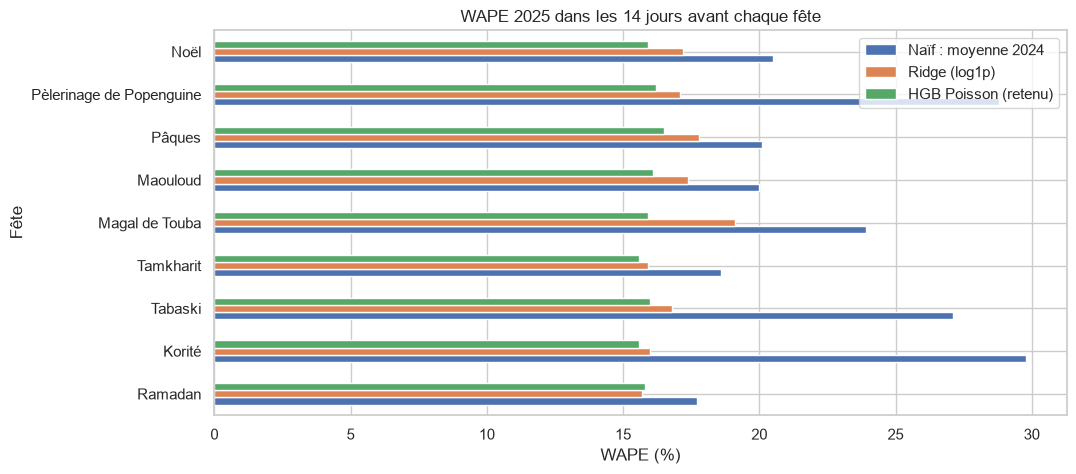

In [36]:
garde = ~test_pred["quantite_imputee"]
lignes = []
for evenement, n in FETES.items():
    masque = garde & test_pred[f"av_{n}"].between(1, 14)        # 14 jours avant la fête
    ligne = {"evenement": evenement, "lignes": int(masque.sum())}
    for c, nom in NOMS_PREVISIONS.items():
        ligne[nom] = round(wape(test_pred.loc[masque, "quantite"], test_pred.loc[masque, c]), 3)
    lignes.append(ligne)
wape_par_fete = pd.DataFrame(lignes).set_index("evenement")
display(wape_par_fete)

fig, ax = plt.subplots(figsize=(11, 5))
wape_par_fete[["Naïf : moyenne 2024", "Ridge (log1p)", "HGB Poisson (retenu)"]].mul(100).plot.barh(ax=ax)
ax.set_title("WAPE 2025 dans les 14 jours avant chaque fête")
ax.set_xlabel("WAPE (%)")
ax.set_ylabel("Fête")
sauver_figure(fig, "p4_wape_par_fete_2025")
plt.show()

### 4.6 Les modèles sous-estiment-ils les pics ?

totaux prévus et réels sur trois pics de 2025

In [37]:
PICS = [("Tabaski", "betail_mouton"), ("Korité", "dattes"), ("Noël", "jouets_cadeaux")]
lignes = []
for evenement, cat in PICS:
    m = test_pred[f"av_{FETES[evenement]}"].between(1, 7) & (test_pred["categorie"] == cat) & garde
    ligne = {"pic (J-7 à J-1, 10 magasins)": f"{evenement} : {cat}", "reel": test_pred.loc[m, "quantite"].sum()}
    for c, nom in NOMS_PREVISIONS.items():
        ligne[nom] = test_pred.loc[m, c].sum()
    lignes.append(ligne)
# Ligne de comparaison : toute l'année 2025
ligne = {"pic (J-7 à J-1, 10 magasins)": "Toute l'année 2025", "reel": test_pred.loc[garde, "quantite"].sum()}
for c, nom in NOMS_PREVISIONS.items():
    ligne[nom] = test_pred.loc[garde, c].sum()
lignes.append(ligne)

pics = pd.DataFrame(lignes).set_index("pic (J-7 à J-1, 10 magasins)")
print("Totaux (unités) :")
display(pics.round(0))
print("Écart au réel (%) :")
display(pics.drop(columns="reel").div(pics["reel"], axis=0).sub(1).mul(100).round(1))

Totaux (unités) :


,reel,Naïf : 364 j avant,Naïf : moyenne 2024,Ridge (log1p),HGB quadratique (log1p),HGB Poisson (retenu)
"pic (J-7 à J-1, 10 magasins)",,,,,,
Tabaski : betail_mouton,184.0,42.0,23.0,139.0,140.0,146.0
Korité : dattes,2936.0,2828.0,914.0,2854.0,2770.0,2830.0
Noël : jouets_cadeaux,2538.0,2472.0,646.0,2266.0,2293.0,2440.0
Toute l'année 2025,6985183.0,6850893.0,6851254.0,6791032.0,6681675.0,6842978.0


Écart au réel (%) :


,Naïf : 364 j avant,Naïf : moyenne 2024,Ridge (log1p),HGB quadratique (log1p),HGB Poisson (retenu)
"pic (J-7 à J-1, 10 magasins)",,,,,
Tabaski : betail_mouton,-77.2,-87.6,-24.7,-23.9,-20.6
Korité : dattes,-3.7,-68.9,-2.8,-5.7,-3.6
Noël : jouets_cadeaux,-2.6,-74.6,-10.7,-9.6,-3.9
Toute l'année 2025,-1.9,-1.9,-2.8,-4.3,-2.0


courbe autour de la Tabaski 2025

Figure enregistrée : p4_tabaski_2025_reel_prevu.png


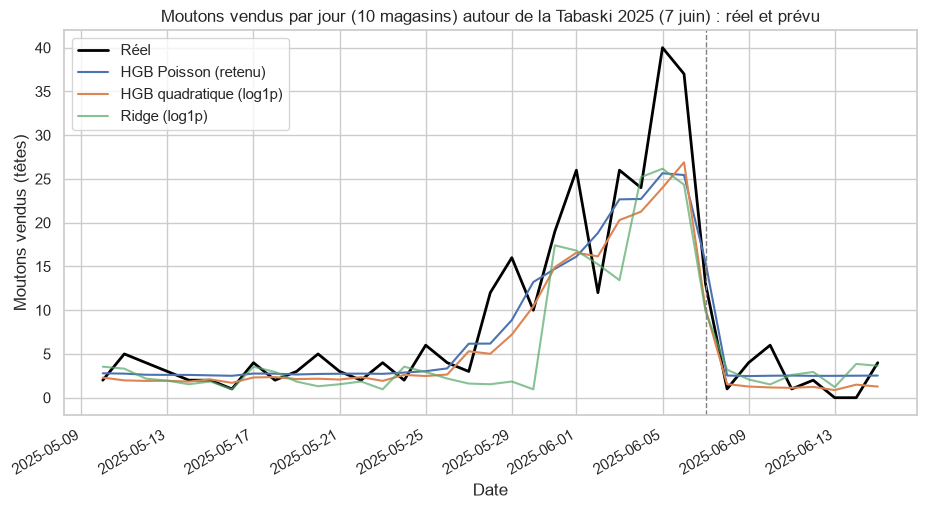

In [38]:
autour = test_pred[(test_pred["categorie"] == "betail_mouton")
                   & test_pred["date"].between("2025-05-10", "2025-06-15")]
courbe = autour.groupby("date")[["quantite", "pred_hgb_poisson", "pred_hgb_log1p", "pred_ridge"]].sum()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(courbe.index, courbe["quantite"], color="black", linewidth=2, label="Réel")
ax.plot(courbe.index, courbe["pred_hgb_poisson"], label="HGB Poisson (retenu)")
ax.plot(courbe.index, courbe["pred_hgb_log1p"], label="HGB quadratique (log1p)")
ax.plot(courbe.index, courbe["pred_ridge"], label="Ridge (log1p)", alpha=0.7)
ax.axvline(pd.Timestamp("2025-06-07"), color="grey", linestyle="--", linewidth=1)
ax.set_title("Moutons vendus par jour (10 magasins) autour de la Tabaski 2025 (7 juin) : réel et prévu")
ax.set_xlabel("Date")
ax.set_ylabel("Moutons vendus (têtes)")
ax.legend()
fig.autofmt_xdate(sauver_figure(fig, "p4_tabaski_2025_reel_prevu"))
plt.show()

### Conclusion de la partie 4

Après réentraînement sur 2016-2024 et **une seule évaluation sur 2025**, le **HGB Poisson** retenu obtient un WAPE de **15,9 %** sur l'année et de **16,0 %** dans les fenêtres de 14 jours avant une fête. La meilleure référence naïve (moyenne 2024) fait 19,8 % et 22,7 %, et la Ridge 16,4 % et 17,0 %. Ces scores sont très proches de ceux de la validation 2024 : le choix fait en validation se confirme sur le test.

Par fête, le HGB Poisson reste entre 15,6 % (Korité, Tamkharit) et 16,5 % (Pâques). Les références naïves se dégradent au contraire là où les fêtes bougent : la référence « 364 jours » atteint 30,5 % pour la Tabaski et 35,8 % pour Pâques.

**Les modèles sous-estiment bien les pics.** Sur les 7 jours avant la Tabaski 2025, il s'est vendu 184 moutons, contre 146 prévus par le HGB Poisson (−21 %) et 139 à 140 par les deux modèles en log1p (−24 à −25 %). Avant Noël, les jouets sont prévus à −3,9 % par le Poisson, contre −9,6 % à −10,7 % par les modèles en log1p. Pour les dattes de la Korité, l'écart reste faible (−2,8 à −5,7 %).

**Le lien avec la perte est direct.** Avec une cible en log1p, le modèle prévoit en réalité la moyenne du logarithme. En revenant aux quantités par `expm1`, on obtient une valeur plus petite que la moyenne des ventes (inégalité de Jensen), et l'écart grandit là où les ventes sont les plus variables, c'est-à-dire dans les pics. Sur toute l'année 2025, la perte quadratique sur log1p sous-estime ainsi le total de **4,3 %**, contre **2,0 %** pour la perte de Poisson, qui prévoit directement l'espérance du nombre d'unités. **La perte de Poisson est donc le bon choix pour dimensionner des quantités.** Le reste de sous-estimation, les deux derniers jours avant la Tabaski (environ 40 moutons par jour au réel contre 25 prévus), montre qu'un pic court et très concentré reste difficile à prévoir un an à l'avance sans ventes récentes.

## Bonus · Intervalles de prévision (régression quantile) et stock de sécurité
Modèles entraînés sur 2016-2023, évalués sur la validation 2024 (le test 2025 n'est pas réutilisé).

modèles quantiles

In [39]:
fabriques_q = {
    "hgb_q10_valid": lambda: creer_hgb("quantile", JEUX_VARIABLES["avec_fetes"], perte_quantile=0.1),
    "hgb_q90_valid": lambda: creer_hgb("quantile", JEUX_VARIABLES["avec_fetes"], perte_quantile=0.9),
    "hgb_poisson_valid": lambda: creer_hgb("poisson", JEUX_VARIABLES["avec_fetes"]),   # prévision moyenne
}
modeles_q = {}
for nom, fabrique in fabriques_q.items():
    if peut_recharger(chemin_modele(nom)):
        modeles_q[nom] = joblib.load(chemin_modele(nom))
    else:
        modeles_q[nom] = fabrique().fit(train, train["quantite"])
        joblib.dump(modeles_q[nom], chemin_modele(nom))

valid_q = valid[CLE + ["quantite", "quantite_imputee", "fenetre_14j"] + COLS_AV].copy()
valid_q["q10"] = np.clip(modeles_q["hgb_q10_valid"].predict(valid), 0, None)
valid_q["q90"] = np.clip(modeles_q["hgb_q90_valid"].predict(valid), 0, None)
valid_q["q90"] = np.maximum(valid_q["q90"], valid_q["q10"])      # garde q10 <= q90
valid_q["moyenne"] = np.clip(modeles_q["hgb_poisson_valid"].predict(valid), 0, None)
g = valid_q[~valid_q["quantite_imputee"]]                        # hors lignes imputées


def couverture(d):
    """Part des ventes réelles dans l'intervalle [q10, q90] et au-dessus des niveaux de stock."""
    return pd.Series({
        "lignes": len(d),
        "dans_intervalle_pct": 100 * ((d["quantite"] >= d["q10"]) & (d["quantite"] <= d["q90"])).mean(),
        "au_dessus_q90_pct": 100 * (d["quantite"] > d["q90"]).mean(),
        "au_dessus_moyenne_pct": 100 * (d["quantite"] > d["moyenne"]).mean(),
    })


tableau_couverture = pd.DataFrame({
    "Toute l'année 2024": couverture(g),
    "Fenêtres 14 j avant une fête": couverture(g[g["fenetre_14j"]]),
    "Hors fenêtres": couverture(g[~g["fenetre_14j"]]),
}).T.round(1)
tableau_couverture

,lignes,dans_intervalle_pct,au_dessus_q90_pct,au_dessus_moyenne_pct
Toute l'année 2024,54800.0,74.9,12.0,48.7
Fenêtres 14 j avant une fête,18417.0,75.7,11.7,48.0
Hors fenêtres,36383.0,74.6,12.2,49.1


stock de sécurité sur les trois pics de 2024

In [40]:
lignes = []
for evenement, cat in PICS:
    d = g[g[f"av_{FETES[evenement]}"].between(1, 7) & (g["categorie"] == cat)]
    for nom_stock, col in [("Prévision moyenne (Poisson)", "moyenne"), ("Quantile 90 %", "q90")]:
        lignes.append({
            "pic 2024 (J-7 à J-1, 10 magasins)": f"{evenement} : {cat}",
            "stock journalier": nom_stock,
            "ventes_reelles": int(d["quantite"].sum()),
            "stock_total": int(round(d[col].sum())),
            "jours_en_rupture_pct": round(100 * (d["quantite"] > d[col]).mean(), 1),
            "unites_manquantes": int(round((d["quantite"] - d[col]).clip(lower=0).sum())),
        })
stock_securite = pd.DataFrame(lignes).set_index(["pic 2024 (J-7 à J-1, 10 magasins)", "stock journalier"])
stock_securite.to_parquet(chemin_parquet("stock_securite_2024"))
stock_securite

ventes_reelles  stock_total  jours_en_rupture_pct  unites_manquantes
pic 2024 (J-7 à J-1, 10 magasins) stock journalier                                                                                 
Tabaski : betail_mouton           Prévision moyenne (Poisson)             170          155                  50.0                 51
                                  Quantile 90 %                           170          318                  12.9                  7
Korité : dattes                   Prévision moyenne (Poisson)            2754         2737                  48.6                290
                                  Quantile 90 %                          2754         3540                  14.3                 60
Noël : jouets_cadeaux             Prévision moyenne (Poisson)            2557         2273                  55.7                451
                                  Quantile 90 %                          2557         3111                  20.0                107

intervalle autour de la Tabaski 2024 (Dakar Plateau)

Figure enregistrée : bonus_intervalle_quantile_tabaski_2024.png


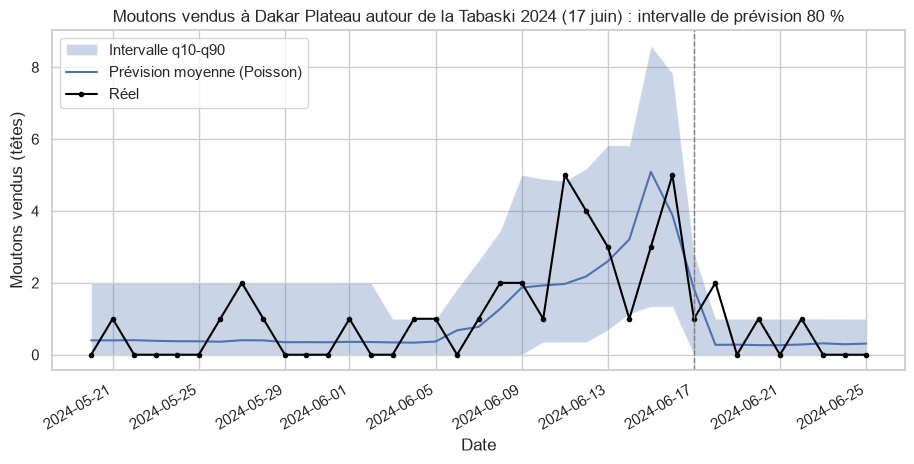

In [41]:
exemple = valid_q[(valid_q["magasin_id"] == "M01") & (valid_q["categorie"] == "betail_mouton")
                  & valid_q["date"].between("2024-05-20", "2024-06-25")]

fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(exemple["date"], exemple["q10"], exemple["q90"], alpha=0.3, label="Intervalle q10-q90")
ax.plot(exemple["date"], exemple["moyenne"], label="Prévision moyenne (Poisson)")
ax.plot(exemple["date"], exemple["quantite"], color="black", marker="o", markersize=3, label="Réel")
ax.axvline(pd.Timestamp("2024-06-17"), color="grey", linestyle="--", linewidth=1)
ax.set_title("Moutons vendus à Dakar Plateau autour de la Tabaski 2024 (17 juin) : intervalle de prévision 80 %")
ax.set_xlabel("Date")
ax.set_ylabel("Moutons vendus (têtes)")
ax.legend()
fig.autofmt_xdate()
sauver_figure(fig, "bonus_intervalle_quantile_tabaski_2024")
plt.show()

### Conclusion du bonus quantiles

Deux HGB quantiles (10 % et 90 %), entraînés sur 2016-2023 et évalués sur 2024, encadrent un intervalle de prévision qui devrait contenir 80 % des ventes. En pratique, il en contient **74,9 %**, et 12,0 % des ventes dépassent le quantile 90 % (pour 10 % attendus). Les intervalles sont donc légèrement trop étroits, et ce défaut est le même dans les fenêtres de fête (75,7 %) et en dehors (74,6 %). Pour le dimensionnement, la différence est nette. Stocker chaque jour la prévision moyenne (Poisson) expose à une rupture **environ un jour sur deux** (49 à 56 % des jours sur les trois pics de 2024). Stocker le quantile 90 % ramène les ruptures à 13 % des jours pour le mouton avant la Tabaski, à 14 % pour les dattes avant la Korité et à 20 % pour les jouets avant Noël. Les unités manquantes passent alors de 51 à 7 moutons, de 290 à 60 kg de dattes et de 451 à 107 jouets. Le prix de cette sécurité est un stock plus élevé : environ deux fois la prévision moyenne pour le mouton (318 contre 155 têtes), +29 % pour les dattes et +37 % pour les jouets. Comme le quantile 90 % est appliqué jour par jour, ce stock est une borne haute. Noël reste le pic le moins bien couvert (20 % de jours en rupture).

## Partie 5 · Qui s'endette après la fête ?

### 5.1 Chargement, audit rapide et nettoyage de l'enquête

chargement et audit

In [42]:
enquete_brute = pd.read_csv(DOSSIER_RAW / "enquete_menages.csv")
POSTES = ["dep_alimentation_fcfa", "dep_habillement_fcfa", "dep_betail_fcfa",
          "dep_transport_ziara_fcfa", "dep_cadeaux_dons_fcfa"]

print("Dimensions :", enquete_brute.shape, "| Ménages distincts :", enquete_brute["menage_id"].nunique())
print("Doublons (hors identifiant) :", int(enquete_brute.drop(columns="enquete_id").duplicated().sum()))
print("Régions mal saisies (casse) :", int((enquete_brute["region"] != enquete_brute["region"].str.title()).sum()))
print("Valeurs manquantes :", enquete_brute.isna().sum()[lambda s: s > 0].to_dict())
ecart = (enquete_brute["depense_totale_fcfa"] - enquete_brute[POSTES].sum(axis=1)).abs()
print("Écart total / somme des postes : max", int(ecart.max()), "FCFA, sur", int((ecart > 0).sum()), "lignes")
# Les vides de confrerie correspondent-ils aux ménages chrétiens ?
print(pd.crosstab(enquete_brute["religion"], enquete_brute["confrerie"].isna(), colnames=["confrerie vide"]))
# achat_mouton n'est renseigné que pour la Tabaski ?
print(enquete_brute.groupby("evenement")["achat_mouton"].apply(lambda s: s.notna().mean()).round(2).to_dict())

Dimensions : (49406, 21) | Ménages distincts : 12000
Doublons (hors identifiant) : 0
Régions mal saisies (casse) : 60
Valeurs manquantes : {'revenu_mensuel_fcfa': 741, 'confrerie': 2227, 'achat_mouton': 37806}
Écart total / somme des postes : max 1000 FCFA, sur 13910 lignes
confrerie vide  False  True 
religion                    
chrétien            0   2227
musulman        47179      0
{'Korité (avec Ramadan)': 0.0, 'Magal de Touba': 0.0, 'Maouloud': 0.0, 'Noël': 0.0, 'Pâques': 0.0, 'Pèlerinage de Popenguine': 0.0, 'Tabaski': 1.0, 'Tamkharit': 0.0}


nettoyage et variables

In [43]:
def preparer_enquete(brute):
    """Nettoie l'enquête et ajoute les variables dérivées (parts des postes, effort)."""
    e = brute.copy()
    e["region"] = e["region"].str.title()                                    # DAKAR -> Dakar
    e["confrerie"] = e["confrerie"].fillna("aucune (ménage chrétien)")       # vide = sans objet
    e["achat_mouton"] = e["achat_mouton"].fillna(0)                          # hors Tabaski : pas d'achat
    total = e["depense_totale_fcfa"].where(e["depense_totale_fcfa"] > 0)
    for p in POSTES:
        e["part_" + p.removeprefix("dep_").removesuffix("_fcfa")] = e[p] / total
    e["log_depense"] = np.log1p(e["depense_totale_fcfa"])
    e["log_revenu"] = np.log(e["revenu_mensuel_fcfa"])                       # reste NaN si revenu manquant
    e["log_effort"] = np.log((e["depense_totale_fcfa"] + 1) / e["revenu_mensuel_fcfa"])
    return e


enquete = preparer_enquete(enquete_brute)
enquete.to_parquet(chemin_parquet("enquete_propre"), index=False)
print("Régions :", sorted(enquete["region"].unique()))
print("Taux d'endettement global :", round(100 * enquete["endette_apres_fete"].mean(), 1), "%")

Régions : ['Dakar', 'Diourbel', 'Fatick', 'Kaffrine', 'Kaolack', 'Kolda', 'Kédougou', 'Louga', 'Matam', 'Saint-Louis', 'Sédhiou', 'Tambacounda', 'Thiès', 'Ziguinchor']
Taux d'endettement global : 20.1 %


### 5.2 Dépense médiane et taux d'endettement par fête et par mode de financement

statistiques descriptives

,menages,depense_mediane_fcfa,effort_median,taux_endettement_pct
evenement,,,,
Tabaski,11600,246000.0,1.54,44.94
Korité (avec Ramadan),11532,140500.0,0.87,22.26
Magal de Touba,3861,87500.0,0.55,12.74
Maouloud,4862,57000.0,0.35,9.46
Pèlerinage de Popenguine,287,37500.0,0.22,8.36
Noël,3564,24000.0,0.13,8.14
Tamkharit,11298,17000.0,0.10,6.44
Pâques,2402,15000.0,0.08,6.12


,menages,depense_mediane_fcfa,effort_median,taux_endettement_pct
financement_principal,,,,
crédit,8027,131000.0,0.98,45.85
tontine,10645,69000.0,0.48,15.53
épargne,21029,66500.0,0.47,15.28
aide familiale,5368,69250.0,0.48,15.15
transfert diaspora,4337,69500.0,0.49,12.94


Figure enregistrée : p5_endettement_fete_financement.png


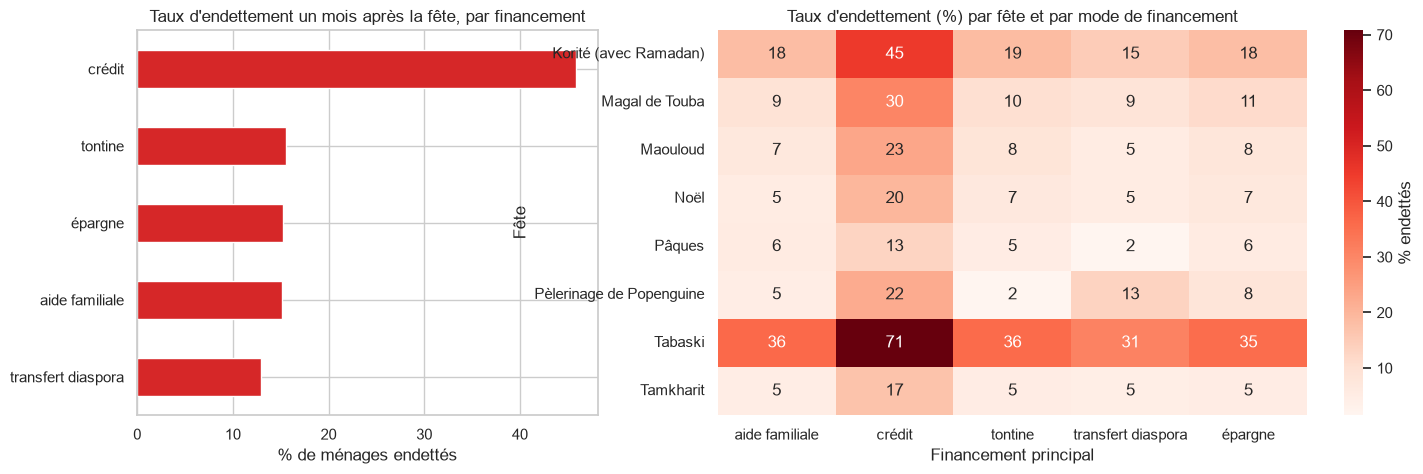

In [44]:
def resume_groupe(colonne):
    return (enquete.groupby(colonne)
            .agg(menages=("enquete_id", "size"),
                 depense_mediane_fcfa=("depense_totale_fcfa", "median"),
                 effort_median=("log_effort", lambda s: np.exp(s.median())),     # dépense / revenu mensuel
                 taux_endettement_pct=("endette_apres_fete", lambda s: 100 * s.mean()))
            .round(2).sort_values("taux_endettement_pct", ascending=False))


display(resume_groupe("evenement"))
display(resume_groupe("financement_principal"))

croise = (enquete.pivot_table(index="evenement", columns="financement_principal",
                              values="endette_apres_fete", aggfunc="mean") * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1.6]})
resume_groupe("financement_principal")["taux_endettement_pct"].sort_values().plot.barh(ax=axes[0], color="tab:red")
axes[0].set(title="Taux d'endettement un mois après la fête, par financement", xlabel="% de ménages endettés", ylabel="")
sns.heatmap(croise, annot=True, fmt=".0f", cmap="Reds", ax=axes[1], cbar_kws={"label": "% endettés"})
axes[1].set(title="Taux d'endettement (%) par fête et par mode de financement", xlabel="Financement principal", ylabel="Fête")
sauver_figure(fig, "p5_endettement_fete_financement")
plt.show()

### 5.3 Régression logistique et HistGradientBoostingClassifier (entraînement 2016-2023, test 2024-2025)
Ces deux premiers modèles incluent la religion et la confrérie, uniquement pour l'analyse d'équité. Le modèle livré n'en contiendra pas.

modèles de classification

In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.inspection import permutation_importance

CIBLE = "endette_apres_fete"
NUM_ENQ = ["taille_menage", "log_revenu", "log_depense", "log_effort", "membre_diaspora", "paiement_mobile",
           "achat_mouton", "part_alimentation", "part_habillement", "part_betail", "part_transport_ziara",
           "part_cadeaux_dons"]
CAT_ENQ = ["region", "milieu", "evenement", "financement_principal"]
SENSIBLES = ["religion", "confrerie"]

train_e = enquete[enquete["annee"] <= 2023]
test_e = enquete[enquete["annee"] >= 2024]
print("Entraînement :", len(train_e), "| Test :", len(test_e),
      "| Taux d'endettement test :", round(100 * test_e[CIBLE].mean(), 1), "%")


def creer_logit(cats, nums):
    """Régression logistique : imputation médiane + indicateur, standardisation, one-hot (dans le Pipeline)."""
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), nums),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cats),
    ])
    return Pipeline([("prep", prep), ("logit", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])


def creer_hgb_clf(cats, nums):
    """HGB classifieur : catégories encodées en entiers, valeurs manquantes gérées nativement."""
    prep = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cats),
        ("num", "passthrough", nums),
    ])
    clf = HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=1.0,
        categorical_features=list(range(len(cats))), early_stopping=False, random_state=RANDOM_STATE)
    return Pipeline([("prep", prep), ("hgb", clf)])


def scores_classif(y, proba, nom):
    return {"modele": nom, "roc_auc": round(roc_auc_score(y, proba), 4),
            "pr_auc": round(average_precision_score(y, proba), 4), "brier": round(brier_score_loss(y, proba), 4)}


def entrainer_ou_charger(nom, fabrique, donnees_train):
    if peut_recharger(chemin_modele(nom)):
        return joblib.load(chemin_modele(nom))
    modele = fabrique().fit(donnees_train, donnees_train[CIBLE])
    joblib.dump(modele, chemin_modele(nom))
    return modele


modeles_e = {
    "Logistique (avec religion, confrérie)": entrainer_ou_charger(
        "logit_complet", lambda: creer_logit(CAT_ENQ + SENSIBLES, NUM_ENQ), train_e),
    "HGB (avec religion, confrérie)": entrainer_ou_charger(
        "hgb_clf_complet", lambda: creer_hgb_clf(CAT_ENQ + SENSIBLES, NUM_ENQ), train_e),
}
probas_e = {nom: m.predict_proba(test_e)[:, 1] for nom, m in modeles_e.items()}

resultats_e = [scores_classif(test_e[CIBLE], p, nom) for nom, p in probas_e.items()]
# Repère : un modèle qui prédirait toujours le taux moyen de l'entraînement
taux_train = train_e[CIBLE].mean()
resultats_e.append({"modele": "Repère : taux constant", "roc_auc": 0.5,
                    "pr_auc": round(test_e[CIBLE].mean(), 4),
                    "brier": round(brier_score_loss(test_e[CIBLE], np.full(len(test_e), taux_train)), 4)})
pd.DataFrame(resultats_e)

Entraînement : 39462 | Test : 9944 | Taux d'endettement test : 20.0 %


,modele,roc_auc,pr_auc,brier
0,"Logistique (avec religion, confrérie)",0.8207,0.6075,0.1161
1,"HGB (avec religion, confrérie)",0.8185,0.6112,0.1157
2,Repère : taux constant,0.5000,0.1997,0.1598


importance par permutation

Meilleur modèle : Logistique (avec religion, confrérie)
Figure enregistrée : p5_importance_permutation.png


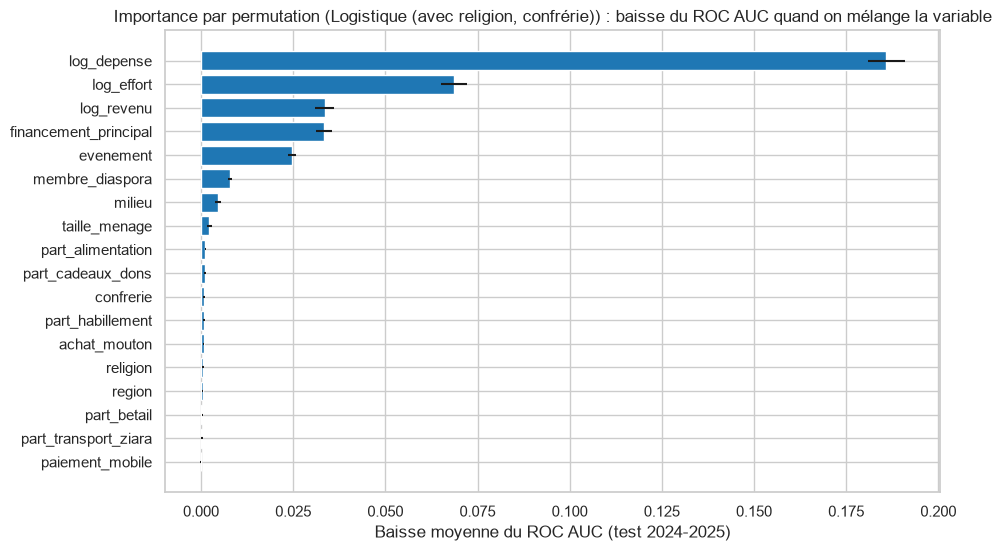

,variable,baisse_auc,ecart_type
8,log_depense,0.1859,0.0051
9,log_effort,0.0687,0.0035
7,log_revenu,0.0335,0.0027
3,financement_principal,0.0334,0.0022
2,evenement,0.0246,0.0012
10,membre_diaspora,0.0078,0.0005
1,milieu,0.0046,0.0007
6,taille_menage,0.0023,0.0007
13,part_alimentation,0.0012,0.0002
17,part_cadeaux_dons,0.0010,0.0003


In [46]:
# Meilleur modèle selon le ROC AUC sur le test 2024-2025
nom_meilleur = max(probas_e, key=lambda n: roc_auc_score(test_e[CIBLE], probas_e[n]))
meilleur_type = "hgb" if nom_meilleur.startswith("HGB") else "logit"
print("Meilleur modèle :", nom_meilleur)

if peut_recharger(chemin_parquet("importance_permutation")):
    importance = pd.read_parquet(chemin_parquet("importance_permutation"))
else:
    colonnes = CAT_ENQ + SENSIBLES + NUM_ENQ
    r = permutation_importance(modeles_e[nom_meilleur], test_e[colonnes], test_e[CIBLE], scoring="roc_auc",
                               n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    importance = (pd.DataFrame({"variable": colonnes, "baisse_auc": r.importances_mean, "ecart_type": r.importances_std})
                  .sort_values("baisse_auc", ascending=False))
    importance.to_parquet(chemin_parquet("importance_permutation"), index=False)

fig, ax = plt.subplots(figsize=(10, 6))
imp = importance.sort_values("baisse_auc")
ax.barh(imp["variable"], imp["baisse_auc"], xerr=imp["ecart_type"], color="tab:blue")
ax.set_title(f"Importance par permutation ({nom_meilleur}) : baisse du ROC AUC quand on mélange la variable")
ax.set_xlabel("Baisse moyenne du ROC AUC (test 2024-2025)")
sauver_figure(fig, "p5_importance_permutation")
plt.show()
importance.round(4)

### 5.4 Question d'équité : le meilleur modèle sans la religion ni la confrérie

modèle sans variables sensibles, et analyse par groupe

In [47]:
fabrique_sans = ((lambda: creer_hgb_clf(CAT_ENQ, NUM_ENQ)) if meilleur_type == "hgb"
                 else (lambda: creer_logit(CAT_ENQ, NUM_ENQ)))
modele_livre = entrainer_ou_charger(f"{meilleur_type}_clf_sans_sensibles", fabrique_sans, train_e)   # modèle livré
proba_sans = modele_livre.predict_proba(test_e)[:, 1]
proba_avec = probas_e[nom_meilleur]

display(pd.DataFrame([scores_classif(test_e[CIBLE], proba_avec, nom_meilleur),
                      scores_classif(test_e[CIBLE], proba_sans, nom_meilleur.replace("avec", "SANS"))]))

# Performance et risque prédit par groupe, avec et sans les variables sensibles
analyse = test_e[["religion", "confrerie", CIBLE]].assign(proba_avec=proba_avec, proba_sans=proba_sans)


def par_groupe(colonne):
    return (analyse.groupby(colonne)
            .apply(lambda g: pd.Series({
                "menages": len(g),
                "taux_reel_pct": 100 * g[CIBLE].mean(),
                "risque_predit_avec_pct": 100 * g["proba_avec"].mean(),
                "risque_predit_sans_pct": 100 * g["proba_sans"].mean(),
                "auc_avec": roc_auc_score(g[CIBLE], g["proba_avec"]),
                "auc_sans": roc_auc_score(g[CIBLE], g["proba_sans"]),
            }))
            .round(3))


display(par_groupe("religion"))
display(par_groupe("confrerie"))

# Les autres variables permettent-elles de retrouver la religion ? (effet de « proxy »)
proxy = creer_hgb_clf(CAT_ENQ, NUM_ENQ).fit(train_e, (train_e["religion"] == "chrétien").astype(int))
auc_proxy = roc_auc_score((test_e["religion"] == "chrétien").astype(int), proxy.predict_proba(test_e)[:, 1])
print(f"ROC AUC pour retrouver la religion à partir des autres variables : {auc_proxy:.3f}")
print("Religion des ménages par fête (%) :")
display((pd.crosstab(enquete["evenement"], enquete["religion"], normalize="index") * 100).round(1))

,modele,roc_auc,pr_auc,brier
0,"Logistique (avec religion, confrérie)",0.8207,0.6075,0.1161
1,"Logistique (SANS religion, confrérie)",0.8211,0.6059,0.1164


,menages,taux_reel_pct,risque_predit_avec_pct,risque_predit_sans_pct,auc_avec,auc_sans
religion,,,,,,
chrétien,421.0,10.926,10.384,15.021,0.673,0.682
musulman,9523.0,20.372,22.347,22.044,0.823,0.824


,menages,taux_reel_pct,risque_predit_avec_pct,risque_predit_sans_pct,auc_avec,auc_sans
confrerie,,,,,,
aucune (ménage chrétien),421.0,10.926,10.384,15.021,0.673,0.682
autre,408.0,22.304,22.627,23.063,0.838,0.837
khadre,517.0,21.663,22.967,22.404,0.804,0.803
layène,124.0,21.774,20.396,19.495,0.867,0.870
mouride,3717.0,19.532,22.109,21.696,0.825,0.825
tidiane,4757.0,20.685,22.492,22.255,0.822,0.822


ROC AUC pour retrouver la religion à partir des autres variables : 0.999
Religion des ménages par fête (%) :


religion,chrétien,musulman
evenement,,
Korité (avec Ramadan),2.0,98.0
Magal de Touba,0.0,100.0
Maouloud,0.0,100.0
Noël,19.7,80.3
Pâques,29.2,70.8
Pèlerinage de Popenguine,100.0,0.0
Tabaski,2.6,97.4
Tamkharit,0.0,100.0


### Conclusion de la partie 5

**Qui s'endette ?** Un mois après la fête, 20,1 % des ménages déclarent une dette non remboursée. La **Tabaski** se détache nettement : la dépense médiane y est de 246 000 FCFA, soit **1,5 fois le revenu mensuel**, et 44,9 % des ménages sont endettés. Viennent ensuite la Korité (140 500 FCFA, 22,3 %) puis les autres fêtes, toutes sous 13 %, jusqu'à Pâques (15 000 FCFA, 6,1 %). Le **financement à crédit** est le principal signal : 45,9 % d'endettés, contre 12,9 à 15,5 % pour l'épargne, la tontine, l'aide familiale ou un transfert de la diaspora.

**Les modèles.** Entraînés sur 2016-2023 et testés sur 2024-2025, la régression logistique (ROC AUC 0,821 ; PR AUC 0,608 ; Brier 0,116) et le HGB (0,819 ; 0,611 ; 0,116) sont équivalents, et nettement meilleurs que le repère constant (0,5 ; 0,200 ; 0,160). **Choix : la régression logistique**, plus simple à expliquer. L'importance par permutation montre que le risque dépend surtout du **montant dépensé** (baisse d'AUC de 0,186), de l'**effort** dépense/revenu (0,069), du revenu (0,034), du mode de financement (0,033) et de la fête (0,025). La religion (0,0005) et la confrérie (0,0009) ne pèsent presque rien.

**Équité.** Réentraîné sans la religion ni la confrérie, le modèle garde la même performance (ROC AUC 0,821, Brier 0,116) : ces variables n'apportent rien en moyenne, et un organisme de microfinance ne doit pas les utiliser. Les retirer ne rend pas pour autant le modèle neutre. Les autres variables permettent de retrouver la religion presque parfaitement (ROC AUC de 0,999), surtout par la fête : tous les ménages du pèlerinage de Popenguine sont chrétiens, et tous ceux du Magal, du Maouloud et de la Tamkharit sont musulmans. Le modèle sans variables sensibles **surestime** aussi le risque des ménages chrétiens (15,0 % prédit contre 10,9 % observé, contre 10,4 % avec la religion), et il les classe moins bien (AUC de 0,68 dans ce groupe contre 0,82 chez les ménages musulmans). Ce groupe ne compte toutefois que 421 ménages en test. La conclusion pour l'organisme est donc la suivante. Il peut utiliser le modèle **sans** religion ni confrérie, mais il doit contrôler régulièrement le calibrage et les taux d'erreur **par groupe** et surveiller les variables qui servent de substitut, comme la fête. Il doit aussi s'en servir comme aide à la décision plutôt que comme refus automatique, par exemple pour proposer une épargne préalable ou des échéances adaptées avant la Tabaski. Ces données étant fictives, aucune conclusion ne vaut pour une communauté réelle.

## Partie 6 · Profils de dépense des ménages en 2025 (K-means)

agrégation par ménage

In [48]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

e25 = enquete[enquete["annee"] == 2025]
NOMS_POSTES = [p.removeprefix("dep_").removesuffix("_fcfa") for p in POSTES]

profils = e25.groupby("menage_id").agg(
    nb_fetes=("evenement", "size"),
    depense_annuelle_fcfa=("depense_totale_fcfa", "sum"),
    **{p: (p, "sum") for p in POSTES},
    revenu_mensuel_fcfa=("revenu_mensuel_fcfa", "median"),
    milieu=("milieu", "first"),
    taille_menage=("taille_menage", "first"),
    endette_au_moins_une_fois=("endette_apres_fete", "max"),
    part_fetes_a_credit=("financement_principal", lambda s: (s == "crédit").mean()),
)
for p, nom in zip(POSTES, NOMS_POSTES):
    profils[f"part_{nom}"] = profils[p] / profils["depense_annuelle_fcfa"]
profils["effort"] = np.log(profils["depense_annuelle_fcfa"] / profils["revenu_mensuel_fcfa"])

VARS_KMEANS = [f"part_{nom}" for nom in NOMS_POSTES] + ["effort"]
profils_ok = profils.dropna(subset=VARS_KMEANS).copy()
print("Ménages 2025 :", len(profils), "| exclus (revenu manquant) :", len(profils) - len(profils_ok))
profils_ok[VARS_KMEANS].describe().round(3)

Ménages 2025 : 1200 | exclus (revenu manquant) : 0


,part_alimentation,part_habillement,part_betail,part_transport_ziara,part_cadeaux_dons,effort
count,1200.000,1200.000,1200.000,1200.000,1200.000,1200.000
mean,0.327,0.273,0.210,0.074,0.115,1.080
std,0.062,0.060,0.115,0.030,0.038,0.380
min,0.176,0.132,0.000,0.000,0.058,-0.842
25%,0.286,0.232,0.178,0.050,0.094,0.920
50%,0.315,0.264,0.243,0.072,0.107,1.136
75%,0.356,0.303,0.287,0.092,0.123,1.316
max,0.618,0.585,0.484,0.252,0.389,1.959


choix de k (silhouette et inertie)

,k,silhouette,inertie,plus_petit_groupe
0,2,0.478,4671.929,248
1,3,0.461,3453.867,64
2,4,0.265,2818.165,64
3,5,0.239,2534.664,63
4,6,0.246,2268.792,20
5,7,0.226,2117.994,20
6,8,0.204,1972.059,20


Figure enregistrée : p6_choix_k.png


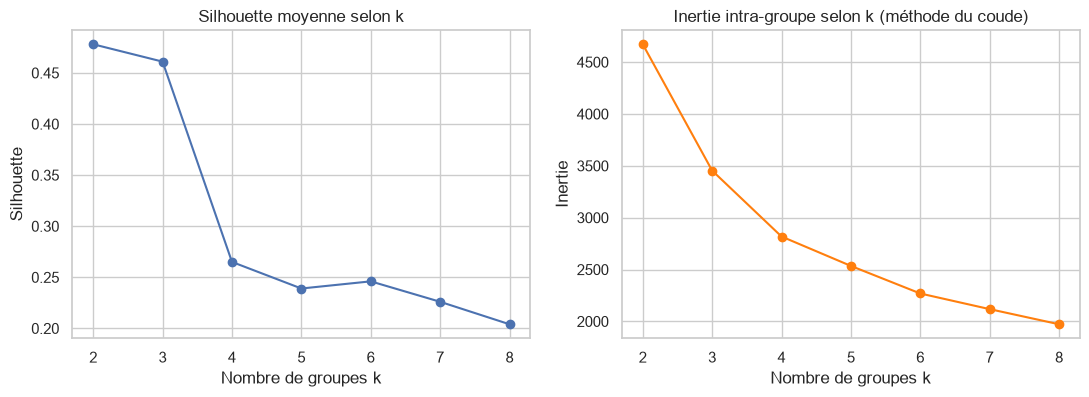

k retenu : 3


In [49]:
lignes = []
for k in range(2, 9):
    pipe_k = Pipeline([("sc", StandardScaler()),
                       ("km", KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE))]).fit(profils_ok[VARS_KMEANS])
    etiquettes = pipe_k["km"].labels_
    lignes.append({"k": k,
                   "silhouette": silhouette_score(pipe_k["sc"].transform(profils_ok[VARS_KMEANS]), etiquettes),
                   "inertie": pipe_k["km"].inertia_,
                   "plus_petit_groupe": int(np.bincount(etiquettes).min())})
choix_k = pd.DataFrame(lignes).round(3)
display(choix_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(choix_k["k"], choix_k["silhouette"], marker="o")
axes[0].set(title="Silhouette moyenne selon k", xlabel="Nombre de groupes k", ylabel="Silhouette")
axes[1].plot(choix_k["k"], choix_k["inertie"], marker="o", color="tab:orange")
axes[1].set(title="Inertie intra-groupe selon k (méthode du coude)", xlabel="Nombre de groupes k", ylabel="Inertie")
sauver_figure(fig, "p6_choix_k")
plt.show()

K_CHOISI = 3   # Choix : silhouette presque égale à k=2 (0,461 contre 0,478), chute nette à k=4 (0,265) ; k=3 ajoute un profil de plus
print("k retenu :", K_CHOISI)

segmentation finale et description des groupes

,menages,part_alimentation_pct,part_habillement_pct,part_betail_pct,part_transport_ziara_pct,part_cadeaux_dons_pct,effort_median,depense_annuelle_mediane,revenu_mensuel_median,nb_fetes_moyen,endettes_pct,fetes_a_credit_pct,urbains_pct
groupe,,,,,,,,,,,,,
0,954,30.42,25.89,26.27,7.15,10.27,3.15,610500.0,197000.0,4.16,64.26,17.22,54.82
1,64,47.47,21.90,0.19,6.36,24.08,1.01,199000.0,192000.0,2.88,31.25,9.38,64.06
2,182,39.57,36.88,0.93,9.10,13.53,3.23,404750.0,121000.0,4.18,63.74,16.85,36.81


Figure enregistrée : p6_profils_depense.png


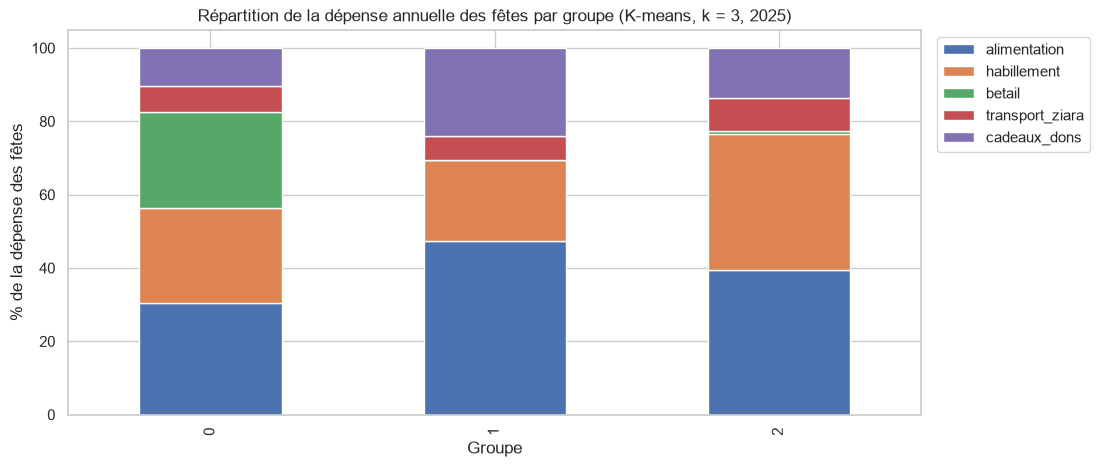

In [50]:
kmeans_final = Pipeline([("sc", StandardScaler()),
                         ("km", KMeans(n_clusters=K_CHOISI, n_init=10, random_state=RANDOM_STATE))])
profils_ok["groupe"] = kmeans_final.fit_predict(profils_ok[VARS_KMEANS])
joblib.dump(kmeans_final, chemin_modele("kmeans_profils_2025"))

description = profils_ok.groupby("groupe").agg(
    menages=("nb_fetes", "size"),
    **{f"part_{nom}_pct": (f"part_{nom}", lambda s: 100 * s.mean()) for nom in NOMS_POSTES},
    effort_median=("effort", lambda s: np.exp(s.median())),            # dépense annuelle / revenu mensuel
    depense_annuelle_mediane=("depense_annuelle_fcfa", "median"),
    revenu_mensuel_median=("revenu_mensuel_fcfa", "median"),
    nb_fetes_moyen=("nb_fetes", "mean"),
    endettes_pct=("endette_au_moins_une_fois", lambda s: 100 * s.mean()),
    fetes_a_credit_pct=("part_fetes_a_credit", lambda s: 100 * s.mean()),
    urbains_pct=("milieu", lambda s: 100 * (s == "urbain").mean()),
).round(2)
profils_ok.to_parquet(chemin_parquet("profils_menages_2025"))
display(description)

fig, ax = plt.subplots(figsize=(11, 5))
description[[f"part_{nom}_pct" for nom in NOMS_POSTES]].plot.bar(stacked=True, ax=ax)
ax.set_title(f"Répartition de la dépense annuelle des fêtes par groupe (K-means, k = {K_CHOISI}, 2025)")
ax.set_xlabel("Groupe")
ax.set_ylabel("% de la dépense des fêtes")
ax.legend(NOMS_POSTES, bbox_to_anchor=(1.01, 1), loc="upper left")
sauver_figure(fig, "p6_profils_depense")
plt.show()

### Conclusion de la partie 6

Pour 2025, les dépenses des 1 200 ménages ont été agrégées sur toutes leurs fêtes. Aucun ménage n'a été exclu, puisque le revenu est connu pour tous en 2025. La segmentation K-means porte sur la part des cinq postes et sur l'effort (log de la dépense annuelle des fêtes rapportée au revenu mensuel), après standardisation. **Choix : k = 3.** Sa silhouette (0,461) est presque égale à celle de k = 2 (0,478), et elle chute à 0,265 dès k = 4. De plus, k = 2 ne fait que séparer les acheteurs de bétail des autres, alors que k = 3 fait apparaître un troisième profil distinct.

- **Groupe 0, ménages de la Tabaski avec mouton** (954 ménages) : 26 % de la dépense va au bétail. La dépense annuelle médiane est de 610 500 FCFA, soit 3,2 fois le revenu mensuel. 64 % sont endettés après au moins une fête, et 55 % sont urbains.
- **Groupe 1, petits budgets tournés vers la table et les cadeaux** (64 ménages) : ils font 2,9 fêtes en moyenne, et l'alimentation (47 %) et les cadeaux et dons (24 %) dominent, sans bétail. L'effort est faible (1,0 fois le revenu mensuel pour 199 000 FCFA), seulement 31 % sont endettés, et 64 % sont urbains.
- **Groupe 2, ménages modestes sans mouton, forte part d'habillement** (182 ménages) : l'habillement représente 37 % de la dépense. C'est le revenu médian le plus bas (121 000 FCFA) pour l'effort le plus élevé (3,2 fois le revenu mensuel). 64 % sont endettés, et 63 % sont ruraux.

C'est le groupe 2 qui mérite une attention particulière : il dépense autant que le groupe 0, relativement à son revenu, avec des moyens nettement plus faibles.

## Partie 7 · Plan 2026 et note de synthèse

### 7.1 Grille 2026 et prévisions
Modèle : HGB Poisson avec variables de fête (choisi en validation), réentraîné sur 2016-2025. Stock prudent : HGB quantile 90 %. Hypothèse : aucune promotion planifiée (plan 2026 non fourni).

grille, réentraînement et prévisions

In [51]:
# Grille 2026 : 365 jours x 10 magasins x 15 catégories
dates_2026 = pd.date_range("2026-01-01", "2026-12-31", freq="D")
grille = (pd.MultiIndex.from_product([dates_2026, magasins["magasin_id"], sorted(CATS_OFFICIELLES)],
                                     names=["date", "magasin_id", "categorie"]).to_frame(index=False))
grille["date"] = grille["date"].astype(ventes["date"].dtype)
grille["magasin_id"] = grille["magasin_id"].astype(ventes["magasin_id"].dtype)
grille["categorie"] = grille["categorie"].astype(ventes["categorie"].dtype)
grille["promo"] = 0          # Choix : plan de promotions 2026 inconnu -> prévision hors promotion
X26 = preparer_features(grille)
print("Grille 2026 :", X26.shape, "| valeurs manquantes :", int(X26[VARS_FETES + NUM_BASE].isna().sum().sum()))

# Réentraînement sur toutes les années connues (2016-2025)
fabriques_2026 = {
    "hgb_poisson_2016_2025": lambda: creer_hgb("poisson", JEUX_VARIABLES["avec_fetes"]),
    "hgb_q90_2016_2025": lambda: creer_hgb("quantile", JEUX_VARIABLES["avec_fetes"], perte_quantile=0.9),
}
modeles_2026 = {}
for nom, fabrique in fabriques_2026.items():
    if peut_recharger(chemin_modele(nom)):
        modeles_2026[nom] = joblib.load(chemin_modele(nom))
    else:
        modeles_2026[nom] = fabrique().fit(donnees, donnees["quantite"])
        joblib.dump(modeles_2026[nom], chemin_modele(nom))

X26["prevision"] = np.clip(modeles_2026["hgb_poisson_2016_2025"].predict(X26), 0, None)
X26["stock_q90"] = np.maximum(np.clip(modeles_2026["hgb_q90_2016_2025"].predict(X26), 0, None), X26["prevision"])
X26[CLE + ["promo", "prevision", "stock_q90"]].to_parquet(chemin_parquet("previsions_2026"), index=False)

total_2025 = donnees.loc[donnees["annee"] == 2025, "quantite"].sum()
print(f"Total prévu 2026 : {X26['prevision'].sum():,.0f} unités | réel 2025 : {total_2025:,.0f} "
      f"({100 * (X26['prevision'].sum() / total_2025 - 1):+.1f} %)")

Grille 2026 : (54750, 31) | valeurs manquantes : 0
Total prévu 2026 : 6,902,339 unités | réel 2025 : 6,999,836 (-1.4 %)


### 7.2 Comparaison au réel 2025 : semaine avant la Tabaski, Magal à Touba, Noël

comparaisons

In [52]:
def comparer_2025_2026(evenement, magasins_sel=None, n_categories=4):
    """Semaine J-7 à J-1 : réel 2025 contre prévision et stock prudent 2026, pour les catégories au plus fort uplift."""
    n = FETES[evenement]
    if magasins_sel is None:      # catégories au plus fort uplift national
        cats = uplift_national[uplift_national["evenement"] == evenement].nlargest(n_categories, "uplift")["categorie"]
    else:                         # catégories au plus fort uplift dans le(s) magasin(s) choisi(s)
        u = uplift_magasin[(uplift_magasin["evenement"] == evenement)
                           & uplift_magasin["magasin_id"].astype(str).isin(magasins_sel)]
        cats = u.nlargest(n_categories, "uplift")["categorie"]
    cats = list(cats.astype(str))

    reel = donnees[(donnees["annee"] == 2025) & donnees[f"av_{n}"].between(1, 7) & donnees["categorie"].isin(cats)]
    prev = X26[X26[f"av_{n}"].between(1, 7) & X26["categorie"].isin(cats)]
    if magasins_sel is not None:
        reel = reel[reel["magasin_id"].astype(str).isin(magasins_sel)]
        prev = prev[prev["magasin_id"].astype(str).isin(magasins_sel)]

    t = pd.DataFrame({
        "reel_2025": reel.groupby("categorie", observed=True)["quantite"].sum(),
        "prevu_2026": prev.groupby("categorie", observed=True)["prevision"].sum(),
        "stock_prudent_2026": prev.groupby("categorie", observed=True)["stock_q90"].sum(),
    }).loc[cats]
    t["evolution_pct"] = 100 * (t["prevu_2026"] / t["reel_2025"] - 1)
    lieu = "10 magasins" if magasins_sel is None else ", ".join(VILLES[m] for m in magasins_sel)
    t.insert(0, "fete_lieu", f"{evenement} ({lieu})")
    return t.reset_index()


comparaison_2026 = pd.concat([
    comparer_2025_2026("Tabaski"),
    comparer_2025_2026("Magal de Touba", magasins_sel=["M05"]),
    comparer_2025_2026("Noël"),
], ignore_index=True)
comparaison_2026["unite"] = comparaison_2026["categorie"].map(categories.set_index("categorie")["unite"])
comparaison_2026.to_parquet(chemin_parquet("comparaison_2025_2026"), index=False)
comparaison_2026.round(1)

,categorie,fete_lieu,reel_2025,prevu_2026,stock_prudent_2026,evolution_pct,unite
0,betail_mouton,Tabaski (10 magasins),184.0,161.0,305.4,-12.5,tête
1,oignons,Tabaski (10 magasins),37237.0,36385.8,43376.3,-2.3,kg
2,tissus_habillement,Tabaski (10 magasins),4167.0,3810.2,5007.8,-8.6,article
3,beaute_coiffure,Tabaski (10 magasins),6407.0,6079.0,7482.9,-5.1,article
4,riz,Magal de Touba (Touba),12558.0,11728.8,12598.3,-6.6,kg
5,boissons,Magal de Touba (Touba),4932.0,4304.4,5759.0,-12.7,bouteille
6,huile,Magal de Touba (Touba),2976.0,2585.6,2981.2,-13.1,litre
7,sucre,Magal de Touba (Touba),3845.0,3059.9,3836.2,-20.4,kg
8,jouets_cadeaux,Noël (10 magasins),2538.0,2324.9,3194.8,-8.4,article
9,volaille,Noël (10 magasins),4260.0,4192.5,5340.9,-1.6,unité


courbe de la Tabaski alignée sur J0 (figure de la note)

Figure enregistrée : p7_tabaski_2025_2026_alignee_j0.png


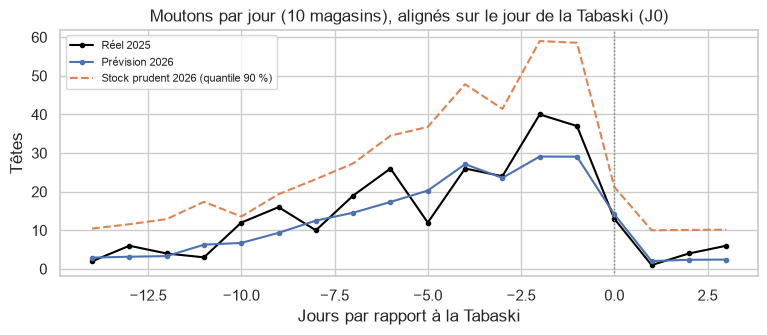

In [53]:
j0_25 = calendrier.loc[(calendrier["evenement"] == "Tabaski") & (calendrier["annee"] == 2025), "date_debut"].iloc[0]
j0_26 = calendrier.loc[(calendrier["evenement"] == "Tabaski") & (calendrier["annee"] == 2026), "date_debut"].iloc[0]

r25 = donnees[(donnees["categorie"] == "betail_mouton")
              & donnees["date"].between(j0_25 - pd.Timedelta(days=14), j0_25 + pd.Timedelta(days=3))]
r25 = r25.groupby("date")["quantite"].sum()
r25.index = (r25.index - j0_25).days                                  # jours relatifs à la Tabaski
p26 = X26[(X26["categorie"] == "betail_mouton")
          & X26["date"].between(j0_26 - pd.Timedelta(days=14), j0_26 + pd.Timedelta(days=3))]
p26 = p26.groupby("date")[["prevision", "stock_q90"]].sum()
p26.index = (p26.index - j0_26).days

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(r25.index, r25.values, color="black", marker="o", markersize=3, label="Réel 2025")
ax.plot(p26.index, p26["prevision"], marker="o", markersize=3, label="Prévision 2026")
ax.plot(p26.index, p26["stock_q90"], linestyle="--", label="Stock prudent 2026 (quantile 90 %)")
ax.axvline(0, color="grey", linestyle=":", linewidth=1)
ax.set_title("Moutons par jour (10 magasins), alignés sur le jour de la Tabaski (J0)")
ax.set_xlabel("Jours par rapport à la Tabaski")
ax.set_ylabel("Têtes")
ax.legend(fontsize=8)
sauver_figure(fig, "p7_tabaski_2025_2026_alignee_j0")
plt.show()

### 7.3 Note de synthèse (Word, une page), générée à partir des résultats

génération de la note Word

In [54]:
from docx import Document
from docx.shared import Pt, Cm
from docx.enum.text import WD_ALIGN_PARAGRAPH


def fr(x, decimales=0):
    """Nombre au format français : espace pour les milliers, virgule décimale."""
    return f"{x:,.{decimales}f}".replace(",", " ").replace(".", ",")


# Chiffres lus dans les résultats du notebook (aucune saisie à la main)
res_test = tableau_test.set_index("modele")
wape_2025 = 100 * res_test.loc["HGB Poisson (retenu)", "wape_annee"]
wape_naif = 100 * res_test.loc["Naïf : moyenne 2024", "wape_annee"]
ecarts_pics = pics.drop(columns="reel").div(pics["reel"], axis=0).sub(1).mul(100)
ecart_tabaski = ecarts_pics.loc["Tabaski : betail_mouton", "HGB Poisson (retenu)"]
couverture_q = tableau_couverture.loc["Toute l'année 2024", "dans_intervalle_pct"]
total_2026 = X26["prevision"].sum()
date_tab_26 = j0_26.strftime("%d/%m/%Y")
date_pop_26 = calendrier.loc[(calendrier["evenement"] == "Pèlerinage de Popenguine")
                             & (calendrier["annee"] == 2026), "date_debut"].iloc[0].strftime("%d/%m/%Y")

doc = Document()
section = doc.sections[0]
section.top_margin = section.bottom_margin = Cm(1.4)
section.left_margin = section.right_margin = Cm(1.8)
section.page_width, section.page_height = Cm(21), Cm(29.7)      # format A4
doc.styles["Normal"].font.name = "Calibri"
doc.styles["Normal"].font.size = Pt(9.5)

titre = doc.add_heading("Note à la direction : quantités à prévoir pour les fêtes de 2026", level=1)
doc.add_paragraph(
    f"Objet : préparer les approvisionnements des 10 points de vente pour 2026. Les prévisions viennent d'un modèle "
    f"de gradient boosting (perte de Poisson) qui n'utilise que ce qui est connu un an à l'avance : le calendrier des "
    f"fêtes, le point de vente et la catégorie. Testé une seule fois sur 2025, il se trompe en moyenne de "
    f"{fr(wape_2025, 1)} % (WAPE), contre {fr(wape_naif, 1)} % pour une simple reconduction de l'année précédente. "
    f"Volume total prévu pour 2026 : {fr(total_2026)} unités, hors promotions."
)

doc.add_heading("Quantités recommandées (semaine J-7 à J-1)", level=2)
colonnes_note = ["Fête et lieu", "Catégorie (unité)", "Réel 2025", "Prévu 2026", "Stock prudent 2026", "Écart 2026/2025"]
table = doc.add_table(rows=1, cols=len(colonnes_note))
table.style = "Table Grid"
for cellule, texte in zip(table.rows[0].cells, colonnes_note):
    cellule.text = texte
    cellule.paragraphs[0].runs[0].bold = True
for _, ligne in comparaison_2026.iterrows():
    cellules = table.add_row().cells
    valeurs = [ligne["fete_lieu"], f"{ligne['categorie']} ({ligne['unite']})", fr(ligne["reel_2025"]),
               fr(ligne["prevu_2026"]), fr(ligne["stock_prudent_2026"]), f"{fr(ligne['evolution_pct'], 1)} %"]
    for cellule, texte in zip(cellules, valeurs):
        cellule.text = texte
for ligne in table.rows:
    for cellule in ligne.cells:
        for paragraphe in cellule.paragraphs:
            for run in paragraphe.runs:
                run.font.size = Pt(8.5)
# Largeur des colonnes : évite que chaque ligne du tableau prenne deux lignes
table.autofit = False
largeurs = [Cm(3.9), Cm(4.4), Cm(2.0), Cm(2.0), Cm(2.8), Cm(2.3)]
for ligne in table.rows:
    for cellule, largeur in zip(ligne.cells, largeurs):
        cellule.width = largeur

doc.add_picture(str(DOSSIER_FIGURES / "p7_tabaski_2025_2026_alignee_j0.png"), width=Cm(14))
doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER

doc.add_heading("Hypothèses retenues", level=2)
for texte in [
    f"Dates des fêtes 2026 du calendrier fourni (Tabaski le {date_tab_26}) ; elles peuvent varier d'un jour selon la lune.",
    "Aucune promotion planifiée : chaque jour de promotion ajoute environ 30 % de ventes sur la catégorie concernée.",
    "Le « stock prudent » est le quantile 90 % journalier : il limite les ruptures à environ un jour sur sept, contre un sur deux avec la prévision moyenne.",
]:
    doc.add_paragraph(texte, style="List Bullet")

doc.add_heading("Limites", level=2)
for texte in [
    f"Toutes les prévisions 2026 sont inférieures au réel 2025 (de {fr(comparaison_2026['evolution_pct'].max(), 1)} % "
    f"à {fr(comparaison_2026['evolution_pct'].min(), 1)} %) : ce n'est pas une baisse attendue de la demande, mais l'effet "
    "de l'hypothèse sans promotion et de la sous-estimation des pics. Le stock prudent couvre le réel 2025 dans presque tous les cas.",
    f"Les pics sont sous-estimés : en 2025, le modèle a prévu {fr(abs(ecart_tabaski), 0)} % de moutons de moins que le réel "
    "dans la semaine de la Tabaski. Pour les produits de fête, commander au niveau du stock prudent.",
    f"Les intervalles de prévision sont un peu étroits ({fr(couverture_q, 1)} % de couverture au lieu de 80 %).",
    f"Le pèlerinage de Popenguine ({date_pop_26}) tombe trois jours avant la Tabaski : les deux demandes se cumulent à Mbour.",
    "Données fictives, à visée pédagogique : ces chiffres ne décrivent aucune communauté réelle.",
]:
    doc.add_paragraph(texte, style="List Bullet")

chemin_note = DOSSIER_RAPPORTS / "note_synthese_2026.docx"
doc.save(chemin_note)
print("Note enregistrée :", chemin_note)

Note enregistrée : c:\Users\User\Desktop\L3S5\Python avance\TP4\fetes-consommation-senegal\reports\note_synthese_2026.docx


### Conclusion de la partie 7

La grille 2026 (54 750 lignes) est prévue par le HGB Poisson réentraîné sur 2016-2025, en supposant qu'aucune promotion n'est planifiée. Le volume total prévu est de 6 902 339 unités, soit −1,4 % par rapport au réel 2025. Voici les quantités prévues pour la semaine J-7 à J-1 :

- **Avant la Tabaski** : 161 moutons (184 vendus en 2025) et 36 386 kg d'oignons (37 237 en 2025).
- **Pendant le Magal à Touba** : 11 729 kg de riz (12 558 en 2025), 4 304 bouteilles de boissons (4 932) et 3 060 kg de sucre (3 845).
- **Avant Noël** : 2 325 jouets (2 538 en 2025) et 4 193 volailles (4 260).

Toutes ces prévisions sont inférieures au réel 2025 (de −1,6 % à −20,4 %). Ce n'est pas une baisse attendue de la demande, mais l'effet cumulé de l'hypothèse sans promotion et de la sous-estimation des pics mesurée en partie 4 (−21 % sur le mouton en 2025). **Recommandation** : commander au niveau de la prévision pour les produits courants, et au niveau du **stock prudent** (quantile 90 %) pour les produits de fête. Ce stock prudent couvre le réel 2025 dans 11 cas sur 12, par exemple 305 moutons et 3 195 jouets ; le sucre à Touba est la seule exception, à 0,2 % près. La note d'une page destinée à la direction est générée par le code (`reports/note_synthese_2026.docx`), puis exportée en PDF.